# Use Foundation Model embeddings in combination with the baselines to predict phenology

Start with the chosen model embeddings + all baselines combinations using RF

Imports

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from scipy.stats import randint, uniform
from xgboost import XGBRegressor

Select folder with data

In [28]:
# Define paths
# Output path
output_dir = Path("output")
# Results path
results_dir = Path("Results")
results_dir.mkdir(parents=True, exist_ok=True)
# Find subfolders in output folder to choose input
subfolders = sorted([f for f in output_dir.iterdir() if f.is_dir()])

if not subfolders:
    raise FileNotFoundError(f"No subdirectories found inside '{output_dir}'.")

if len(subfolders) == 1:
    selected_folder = subfolders[0]
    print(f"Only one folder found. Automatically selected: {selected_folder.name}.")

else:
    print("Available folders in output directory:")
    for idx, folder in enumerate(subfolders, start=1):
        print(f"[{idx}] {folder.name}")

# Get user input
    user_choice = input(f"\nEnter folder number (1-{len(subfolders)}): ").strip()

    if not user_choice.isdigit() or not (1 <= int(user_choice) <= len(subfolders)):
        raise ValueError(
            f"Invalid selection '{user_choice}'. Expected number between 1 and {len(subfolders)}."
        )

    selected_folder = subfolders[int(user_choice) - 1]
    print(f"\n --> Selected folder: {selected_folder.name}")

# Automatically Find Curated Embedding Files Inside Folder
# Matches files like curated_*_tessera_*.csv or curated_*_alphaearth_*.csv
candidate_files = sorted(selected_folder.glob("curated_*_embeddings.csv"))

if not candidate_files:
  raise FileNotFoundError(
      f"No embedding CSV files found inside '{selected_folder.name}'."
  )

if len(candidate_files) == 1:
  chosen_file = candidate_files[0]
  print(f"Only one embedding file found: {chosen_file.name}")
else:
  print("Select which embedding representation to model:")
  for idx, file_path in enumerate(candidate_files, start=1):
    # Tag file type for cleaner display
    name_mapping = {
        "alphaearth": "AlphaEarth (64-d)",
        "tessera": "TESSERA (128-d)",
        "presto": "PRESTO (128-d)",
        "olmo": "OlmoEarth (128-d)"
    }
    emb_tag = next(
        (value for key, value in name_mapping.items()
        if key in file_path.name.lower()),
        "Unknown"
    )

    print(f"[{idx}] {file_path.name}  --> [{emb_tag}]")


  user_file_idx = input(
      f"\nEnter file number (1-{len(candidate_files)}): "
  ).strip()
  if not user_file_idx.isdigit() or not (
      1 <= int(user_file_idx) <= len(candidate_files)
  ):
    raise ValueError(f"Invalid selection '{user_file_idx}'.")
  chosen_file = candidate_files[int(user_file_idx) - 1]

print(f"\n--> Selected modeling file: {chosen_file.name}")

# Save mnodel name for plots, titles and save files
file_name = chosen_file.name.lower()
emb_name = next(
    (key for key in name_mapping if key in file_name),
    "unknown"
    )

    
print(f"Loading data from: {chosen_file}")

folder_parts = selected_folder.name.split("_")
model = emb_name.upper()
country = folder_parts[0].capitalize() # Extract country from folder name
crop = folder_parts[1].upper() # Extract crop from folder name
bbch = f"BBCH {folder_parts[2].replace('bbch', '')}" # Extract BBCH stage from folder name
start_year = folder_parts[3][:4] # Extract start year from folder name
end_year = folder_parts[4][:4] # Extract end year from folder name

final_name = f"{country}, {crop}, {bbch}, Period: {start_year}-{end_year}" # Final name for display and plotting


Available folders in output directory:
[1] france_sbt_bbch39_2017-01-01_2022-12-31
[2] germany_barw_bbch51_2017-01-01_2025-12-31
[3] germany_whbw_bbch0_2017-01-01_2020-12-31

 --> Selected folder: germany_barw_bbch51_2017-01-01_2025-12-31
Select which embedding representation to model:
[1] curated_for_modeling_with_alphaearth_embeddings.csv  --> [AlphaEarth (64-d)]
[2] curated_for_modeling_with_olmo_embeddings.csv  --> [OlmoEarth (128-d)]
[3] curated_for_modeling_with_presto_embeddings.csv  --> [PRESTO (128-d)]
[4] curated_for_modeling_with_tessera_embeddings.csv  --> [TESSERA (128-d)]

--> Selected modeling file: curated_for_modeling_with_alphaearth_embeddings.csv
Loading data from: output\germany_barw_bbch51_2017-01-01_2025-12-31\curated_for_modeling_with_alphaearth_embeddings.csv


Identify the rows with embeddings and delete the rest

In [29]:
df_raw = pd.read_csv(chosen_file, sep=";")
df_raw["Year"] = df_raw["Year"].astype(int)

# Identify feature columns
agdd_cols = [col for col in df_raw.columns if col.startswith("AGDD_doy_")]
gdd_cols = [col for col in df_raw.columns if col.startswith("GDD_doy_")]
ndvi_cols = [col for col in df_raw.columns if col.startswith("NDVI_doy_")]

# Identify embedding columns
if any(col.startswith(f"{emb_name}") for col in df_raw.columns):
  embedding_cols = sorted(
      [c for c in df_raw.columns if c.startswith(f"{emb_name}")]
  )
else:
  raise ValueError(f"File does not contain {model} columns.")

if not agdd_cols:
  raise ValueError(
    "No 'AGDD_doy_' columns found in this file!"
    )

if not gdd_cols:
  raise ValueError(
    "No GDD columns found in this file!"
  )
if not ndvi_cols:
  raise ValueError(
    "No NDVI columns found in this file!"
  )

# Filter strictly to rows containing embeddings
required_cols = (
    ["Year", "Latitude", "Longitude", "DOY"] + embedding_cols + agdd_cols + gdd_cols + ndvi_cols
    )
df_clean = (
    df_raw.dropna(subset=required_cols)
    .sort_values(["Year", "DOY"])
    .reset_index(drop=True)
)

print(f"\nInitial records in file:        {len(df_raw)}")
print(f"Rows with complete {emb_name}:     {len(df_clean)}")
print(f"Years covered:                  {sorted(df_clean['Year'].unique())}")
print(f"{emb_name} channels detected:      {len(embedding_cols)} (0 to {len(embedding_cols) - 1})")
print(f"AGDD channels detected:         {len(agdd_cols)} (1 to 365)")

display(
    df_clean[[
        "Latitude",
        "Longitude",
        "Year",
        "DOY",
        f"{emb_name}_0",
        f"{emb_name}_63",
        "AGDD_doy_120",
        "AGDD_doy_180",
    ]].head()
)

# Create save path for the results
summary_save_path = results_dir / f"{selected_folder.name}" / f"LOYOCV_{model}"
summary_save_path.mkdir(parents=True, exist_ok=True)


Initial records in file:        4461
Rows with complete alphaearth:     4461
Years covered:                  [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
alphaearth channels detected:      64 (0 to 63)
AGDD channels detected:         365 (1 to 365)


,Latitude,Longitude,Year,DOY,alphaearth_0,alphaearth_63,AGDD_doy_120,AGDD_doy_180
0,49.9833,9.15000,2017,110,0.012057,0.108512,592.49636,1584.03722
1,48.9000,8.56667,2017,115,-0.236463,-0.059116,653.97787,1673.00756
2,53.6000,10.18330,2017,115,-0.135886,-0.124567,530.42486,1439.09953
3,51.2000,8.70000,2017,117,-0.124567,-0.098424,400.32896,1248.03487
4,51.4500,7.41667,2017,117,-0.244152,-0.059116,637.69556,1625.12254


Create the models 
1. Selected FM embeddings
2. Selected FM embeddings + Latitude/Longitude
3. Selected FM embeddings + GDD
4. Selected FM embeddings + AGDD
5. Selected FM embeddings + NDVI

In [43]:
# Model 1: TESSERA Embeddings Alone
features_m1_embedding_only = embedding_cols

# Model 2: TESSERA + Spatial Coordinates
features_m2_embedding_spatial = ["Latitude", "Longitude"] + embedding_cols

# Model 3: TESSERA + GDD 
features_m3_embedding_GDD = embedding_cols + gdd_cols

# Model 4: TESSERA + AGDD
features_m4_embedding_AGDD = embedding_cols + agdd_cols

# Model 5: TESSERA + NDVI
features_m5_embedding_NDVI = embedding_cols + ndvi_cols

# Model 6: TESSERA + all
features_m6_embedding_all = embedding_cols + gdd_cols + agdd_cols + ndvi_cols

unique_years = sorted(df_clean["Year"].unique())

# Setup dictionary of baseline feature set
models_to_tune = {
    "M1": features_m1_embedding_only,
    "M2": features_m2_embedding_spatial,
    "M3": features_m3_embedding_GDD,
    "M4": features_m4_embedding_AGDD,
    "M5": features_m5_embedding_NDVI,
    "M6": features_m6_embedding_all,
}

y_all = df_clean["DOY"]
groups_all = df_clean["Year"]
logo = LeaveOneGroupOut()

best_params_dict = {}

# Hyperparameter search space for Random Forest
print("=" * 80)
print(f"RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 (RF - {model})")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_clean[feat_cols]

    # Adjust max_features distribution based on feature count
    if len(feat_cols) <= 3:
        max_feat_dist = [1.0]
    else:
        max_feat_dist = uniform(0.25, 0.50)  # samples between 25% and 75% of features

    param_distributions = {
        "n_estimators": randint(150, 350),
        "max_depth": [None, 12, 18, 25],
        "min_samples_leaf": randint(1, 5),
        "min_samples_split": randint(2, 6),
        "max_features": max_feat_dist,
    }

    rf_search = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rf_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = rf_search.best_params_
    print(f" -> Best LOYOCV MAE: {-rf_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {rf_search.best_params_}")

# Prediction lists for pooled evaluation
m1_preds = []
m2_preds = []
m3_preds = []
m4_preds = []
m5_preds = []
m6_preds = []
actual_doy = []
test_years_list = []
fold_results = []

print(
    f"Model 1 ({model} Only):        "
    f" {len(features_m1_embedding_only)} features"
)
print(
    f"Model 2 ({model} + Spatial):   "
    f" {len(features_m2_embedding_spatial)} features"
)
print(
    f"Model 3 ({model} + GDD ):      "
    f" {len(features_m3_embedding_GDD)} features"
)
print(
    f"Model 4 ({model} + AGDD):      "
    f" {len(features_m4_embedding_AGDD)} features"
)
print(
    f"Model 5 ({model} + NDVI):     "
    f" {len(features_m5_embedding_NDVI)} features"
)
print(
    f"Model 6 ({model} + ALL):      "
    f" {len(features_m6_embedding_all)} features"
)
print(f"Total LOYOCV folds:            {len(unique_years)} years")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 (RF - OLMO)

Tuning M1 (Total Features: 128)...
 -> Best LOYOCV MAE: 6.20 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.3663856702151521), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M2 (Total Features: 130)...
 -> Best LOYOCV MAE: 6.19 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.4132703844029177), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M3 (Total Features: 493)...
 -> Best LOYOCV MAE: 6.52 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.25038938292050716), 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 310}

Tuning M4 (Total Features: 493)...
 -> Best LOYOCV MAE: 5.26 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.4475751180009072), 'min_samples_leaf': 4, 'min_samples_split': 3, 'n_estimators': 244}

Tuning M5 (Total Features: 493)...

TerminatedWorkerError: A worker process managed by the executor was unexpectedly terminated. This could be caused by a segmentation fault while calling the function or by an excessive memory usage causing the Operating System to kill the worker.

Detailed tracebacks of the workers should have been printed to stderr in the executor process if faulthandler was not disabled.

Run the LOYOCV + Random Forest

In [ ]:
print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
  train_mask = df_clean["Year"] != test_year
  test_mask = df_clean["Year"] == test_year

  y_train = df_clean.loc[train_mask, "DOY"]
  y_test = df_clean.loc[test_mask, "DOY"]


  # 1. Fit Model 1: Embedding Only
  rf_m1 = RandomForestRegressor(
    **best_params_dict["M1"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m1.fit(df_clean.loc[train_mask, features_m1_embedding_only], y_train)
  pred_m1 = rf_m1.predict(df_clean.loc[test_mask, features_m1_embedding_only])


  # 2. Fit Model 2: Embedding + Spatial
  rf_m2 = RandomForestRegressor(
    **best_params_dict["M2"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m2.fit(df_clean.loc[train_mask, features_m2_embedding_spatial], y_train)
  pred_m2 = rf_m2.predict(df_clean.loc[test_mask, features_m2_embedding_spatial])


  # 3. Fit Model 3: Embedding + GDD 
  rf_m3 = RandomForestRegressor(
    **best_params_dict["M3"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m3.fit(df_clean.loc[train_mask, features_m3_embedding_GDD], y_train)
  pred_m3 = rf_m3.predict(df_clean.loc[test_mask, features_m3_embedding_GDD])


  # 4. Fit Model 4: Embedding + AGDD 
  rf_m4 = RandomForestRegressor(
    **best_params_dict["M4"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m4.fit(df_clean.loc[train_mask, features_m4_embedding_AGDD], y_train)
  pred_m4 = rf_m4.predict(df_clean.loc[test_mask, features_m4_embedding_AGDD])


  # 5. Fit Model 5: Embedding + NDVI 
  rf_m5 = RandomForestRegressor(
    **best_params_dict["M5"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m5.fit(df_clean.loc[train_mask, features_m5_embedding_NDVI], y_train)
  pred_m5 = rf_m5.predict(df_clean.loc[test_mask, features_m5_embedding_NDVI])


  # 6. Fit Model 6: Embedding + GDD Fusion
  rf_m6 = RandomForestRegressor(
    **best_params_dict["M6"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m6.fit(df_clean.loc[train_mask, features_m6_embedding_all], y_train)
  pred_m6 = rf_m6.predict(df_clean.loc[test_mask, features_m6_embedding_all])

  # Compute fold-level metrics
  mae_m1 = mean_absolute_error(y_test, pred_m1)
  rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

  mae_m2 = mean_absolute_error(y_test, pred_m2)
  rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

  mae_m3 = mean_absolute_error(y_test, pred_m3)
  rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

  mae_m4 = mean_absolute_error(y_test, pred_m4)
  rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

  mae_m5 = mean_absolute_error(y_test, pred_m5)
  rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

  mae_m6 = mean_absolute_error(y_test, pred_m6)
  rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

  fold_results.append({
      "Test_Year": test_year,
      "N_Samples": len(y_test),
      f"M1_{model}Only_MAE": round(mae_m1, 2),
      f"M1_{model}Only_RMSE": round(rmse_m1, 2),
      f"M2_{model}Spatial_MAE": round(mae_m2, 2),
      f"M2_{model}Spatial_RMSE": round(rmse_m2, 2),
      f"M3_{model}GDD_MAE": round(mae_m3, 2),
      f"M3_{model}GDD_RMSE": round(rmse_m3, 2),
      f"M4_{model}AGDD_MAE": round(mae_m4, 2),
      f"M4_{model}AGDD_RMSE": round(rmse_m4, 2),
      f"M5_{model}NDVI_MAE": round(mae_m5, 2),
      f"M5_{model}NDVI_RMSE": round(rmse_m5, 2),
      f"M6_{model}All_MAE": round(mae_m6, 2),
      f"M6_{model}All_RMSE": round(rmse_m6, 2),

  })

  m1_preds.extend(pred_m1)
  m2_preds.extend(pred_m2)
  m3_preds.extend(pred_m3)
  m4_preds.extend(pred_m4)
  m5_preds.extend(pred_m5)
  m6_preds.extend(pred_m6)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
      f"Year {test_year} (N={len(y_test):3d}) | "
      f"{model} Only MAE: {mae_m1:5.2f}d | "
      f"{model} Spatial MAE: {mae_m2:5.2f}d | "
      f"Fusion ({model}+GDD) MAE: {mae_m3:5.2f}d"
      f"Fusion ({model}+AGDD) MAE: {mae_m4:5.2f}d"
      f"Fusion ({model}+NDVI) MAE: {mae_m5:5.2f}d"
      f"Fusion ({model}+All) MAE: {mae_m6:5.2f}d"
  )

print("\nLOYOCV execution finished!")

Starting LOYOCV across 8 folds...

Year 2017 (N=621) | BARW Only MAE:  4.41d | BARW Spatial MAE:  4.39d | Fusion (BARW+GDD) MAE:  4.24dFusion (BARW+AGDD) MAE:  5.27dFusion (BARW+NDVI) MAE:  4.80dFusion (BARW+All) MAE:  4.38d
Year 2018 (N=598) | BARW Only MAE:  4.57d | BARW Spatial MAE:  4.55d | Fusion (BARW+GDD) MAE:  6.33dFusion (BARW+AGDD) MAE:  4.18dFusion (BARW+NDVI) MAE:  4.56dFusion (BARW+All) MAE:  4.49d
Year 2019 (N=592) | BARW Only MAE:  5.82d | BARW Spatial MAE:  5.86d | Fusion (BARW+GDD) MAE:  8.75dFusion (BARW+AGDD) MAE:  6.08dFusion (BARW+NDVI) MAE:  6.03dFusion (BARW+All) MAE:  6.72d
Year 2020 (N=579) | BARW Only MAE:  6.43d | BARW Spatial MAE:  6.45d | Fusion (BARW+GDD) MAE:  7.98dFusion (BARW+AGDD) MAE:  6.84dFusion (BARW+NDVI) MAE:  6.63dFusion (BARW+All) MAE:  7.72d
Year 2021 (N=543) | BARW Only MAE:  6.90d | BARW Spatial MAE:  6.98d | Fusion (BARW+GDD) MAE:  4.78dFusion (BARW+AGDD) MAE:  4.72dFusion (BARW+NDVI) MAE:  7.15dFusion (BARW+All) MAE:  4.56d
Year 2022 (N=52

Print and save results

In [ ]:
df_folds = pd.DataFrame(fold_results)

# Micro-averaged pooled metrics across all 584 observations
overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))

overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))

overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))

overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))

overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))

overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))
print("=" * 85)
print(f"OVERALL LOYOCV BENCHMARK: {model} EMBEDDINGS + BASELINE DATA")
print(
    f"Model 1: {model} Only (128-d)           --> MAE: {overall_m1_mae:5.2f} d |"
    f" RMSE: {overall_m1_rmse:5.2f} d"
)
print(
    f"Model 2: {model} + Spatial (Lat, Lon)   --> MAE: {overall_m2_mae:5.2f} d |"
    f" RMSE: {overall_m2_rmse:5.2f} d"
)
print(
    f"Model 3: {model} + GDD Fusion          --> MAE: {overall_m3_mae:5.2f} d |"
    f" RMSE: {overall_m3_rmse:5.2f} d"
)
print(
    f"Model 4: {model} + AGDD Fusion          --> MAE: {overall_m4_mae:5.2f} d |"
    f" RMSE: {overall_m4_rmse:5.2f} d"
)
print(
    f"Model 5: {model} + NDVI Fusion          --> MAE: {overall_m5_mae:5.2f} d |"
    f" RMSE: {overall_m5_rmse:5.2f} d"
)
print(
    f"Model 6: {model} + All                  --> MAE: {overall_m6_mae:5.2f} d |"
    f" RMSE: {overall_m6_rmse:5.2f} d"
)
print("-" * 85)

display(df_folds)

# Save Results to CSV
summary_save_path = results_dir / f"{selected_folder.name}" / f"LOYOCV_{model}"
summary_save_path.mkdir(parents=True, exist_ok=True)
summary = ( summary_save_path/
    f"{model.lower()}_loyocv_summary_rf.csv"
)
df_folds.to_csv(summary, sep=";", index=False)
print(f"\nFold-level summary saved to: {summary_save_path.resolve()}")

OVERALL LOYOCV BENCHMARK: BARW EMBEDDINGS + BASELINE DATA
Model 1: BARW Only (128-d)           --> MAE:  5.49 d | RMSE:  7.76 d
Model 2: BARW + Spatial (Lat, Lon)   --> MAE:  5.50 d | RMSE:  7.74 d
Model 3: BARW + GDD Fusion          --> MAE:  6.15 d | RMSE:  8.42 d
Model 4: BARW + AGDD Fusion          --> MAE:  5.22 d | RMSE:  7.60 d
Model 5: BARW + NDVI Fusion          --> MAE:  5.62 d | RMSE:  7.90 d
Model 6: BARW + All                  --> MAE:  5.40 d | RMSE:  7.71 d
-------------------------------------------------------------------------------------


,Test_Year,N_Samples,M1_BARWOnly_MAE,M1_BARWOnly_RMSE,M2_BARWSpatial_MAE,M2_BARWSpatial_RMSE,M3_BARWGDD_MAE,M3_BARWGDD_RMSE,M4_BARWAGDD_MAE,M4_BARWAGDD_RMSE,M5_BARWNDVI_MAE,M5_BARWNDVI_RMSE,M6_BARWAll_MAE,M6_BARWAll_RMSE
0,2017,621,4.41,5.97,4.39,5.97,4.24,5.83,5.27,6.93,4.80,6.36,4.38,6.01
1,2018,598,4.57,6.16,4.55,6.11,6.33,7.76,4.18,5.80,4.56,6.16,4.49,6.03
2,2019,592,5.82,7.63,5.86,7.66,8.75,10.37,6.08,7.88,6.03,7.85,6.72,8.46
3,2020,579,6.43,8.02,6.45,8.00,7.98,9.50,6.84,8.37,6.63,8.19,7.72,9.22
4,2021,543,6.90,8.69,6.98,8.73,4.78,6.68,4.72,6.62,7.15,9.09,4.56,6.47
5,2022,529,4.13,5.78,4.10,5.76,4.45,6.06,4.26,5.86,4.15,5.81,4.40,6.01
6,2023,511,4.83,6.69,4.77,6.65,4.01,5.92,4.24,5.98,4.61,6.52,4.01,5.90
7,2024,488,7.13,12.01,7.12,11.97,8.65,12.91,6.15,12.01,7.20,12.07,6.91,11.98



Fold-level summary saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_BARW


Scatter plot figure

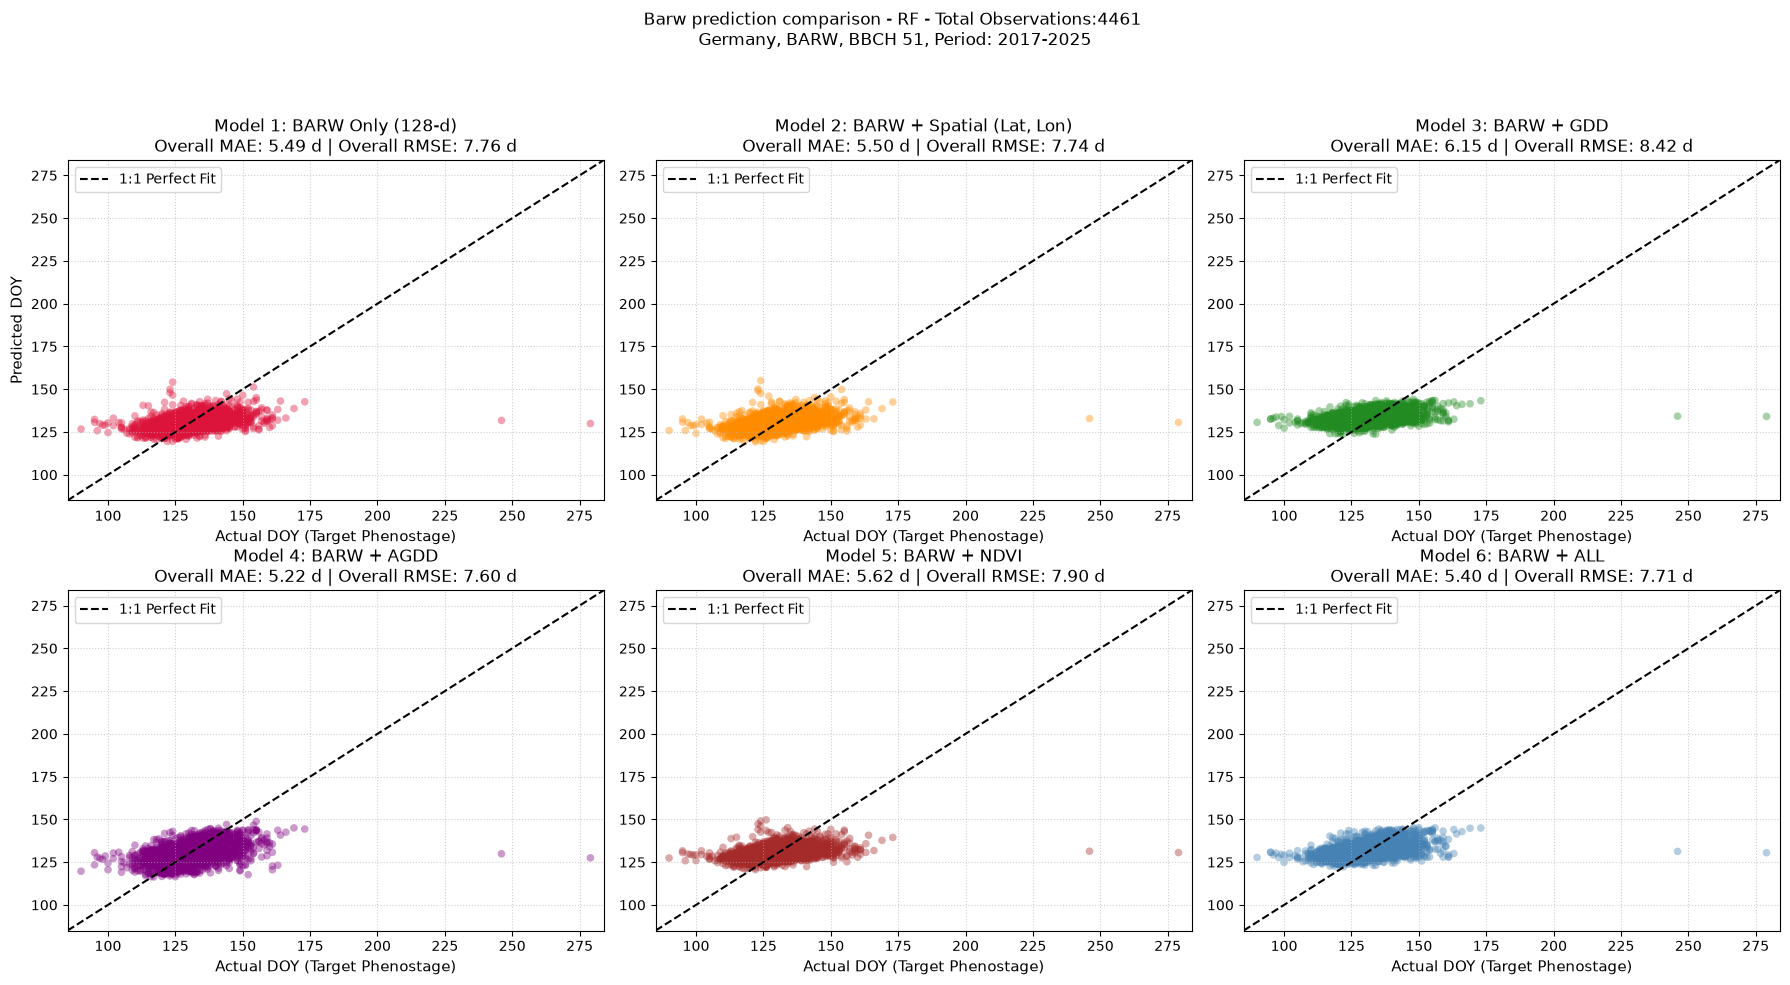

In [ ]:
plt.figure(figsize=(18, 10))
model_configs = [
    (f"Model 1: {model} Only (128-d)", m1_preds, overall_m1_mae, overall_m1_rmse, "crimson"),
    (f"Model 2: {model} + Spatial (Lat, Lon)", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + GDD", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + AGDD", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + NDVI", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL", m6_preds, overall_m6_mae, overall_m6_rmse, "steelblue"),
]

min_val = min(actual_doy) - 5
max_val = max(actual_doy) + 5

for idx, (title, preds, mae_val, rmse_val, color) in enumerate(model_configs, start=1):
    plt.subplot(2, 3, idx)
    plt.scatter(actual_doy, preds, alpha=0.4, color=color, edgecolors="none", s=30)
    plt.plot([min_val, max_val], [min_val, max_val], "k--", lw=1.5, label="1:1 Perfect Fit")
    
    plt.title(f"{title}\nOverall MAE: {mae_val:.2f} d | Overall RMSE: {rmse_val:.2f} d", fontsize=12)
    plt.xlabel("Actual DOY (Target Phenostage)", fontsize=11)
    if idx == 1:
        plt.ylabel("Predicted DOY", fontsize=11)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.suptitle(f"{model} prediction comparison - RF - Total Observations:{len(df_clean)} \n{final_name}")
plt.subplots_adjust(top=0.83)
plt.savefig(summary_save_path / f"scatter_comparison_{model.lower()}_rf.png", dpi=300)
plt.show()

# Use XGBoost for the same predictions (all features)

Create and start the grid search

In [ ]:
# Hyperparameter search space for Random Forest
print("=" * 80)
print(f"RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 FOR XGBOOST - {model}")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_clean[feat_cols]

    # Adapt feature subsampling ratio to feature space size
    if len(feat_cols) <= 3:
        colsample_dist = [1.0]
    else:
        colsample_dist = uniform(0.30, 0.50)  # Randomly samples between 30% and 80%

    xgb_param_distributions = {
        # Ensemble size and shrinkage
        "n_estimators": randint(150, 350),
        "learning_rate": uniform(0.02, 0.08),  # Range: 0.02 to 0.10
        # Tree architecture (keep shallow for small N)
        "max_depth": randint(3, 6),            # Depths 3, 4, 5
        "min_child_weight": randint(2, 7),     # Analogous to min_samples_leaf (2 to 6)
        "gamma": uniform(0.0, 1.5),            # Minimum loss reduction for a split
        # Stochastic sampling
        "subsample": uniform(0.65, 0.30),      # Row subsampling (0.65 to 0.95)
        "colsample_bytree": colsample_dist,    # Column subsampling
        # Regularization
        "reg_alpha": [0.0, 0.1, 1.0],
        "reg_lambda": [1.0, 3.0, 8.0],
    }

    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(
            objective="reg:squarederror",
            eval_metric="mae",
            random_state=42,
            n_jobs=1,  # Keep inner booster single-threaded
        ),
        param_distributions=xgb_param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,  # Parallelize across CV folds/iterations
        verbose=0,
    )

    # Fit using groups to enforce Leave-One-Year-Out validation
    xgb_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = xgb_search.best_params_
    print(f" -> Best LOYOCV MAE: {-xgb_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {xgb_search.best_params_}")

# Prediction lists for pooled evaluation
m1_preds = []
m2_preds = []
m3_preds = []
m4_preds = []
m5_preds = []
m6_preds = []
actual_doy = []
test_years_list = []
fold_results = []

print(
    f"Model 1 ({model} Only):        "
    f" {len(features_m1_embedding_only)} features"
)
print(
    f"Model 2 ({model} + Spatial):   "
    f" {len(features_m2_embedding_spatial)} features"
)
print(
    f"Model 3 ({model} + GDD ):      "
    f" {len(features_m3_embedding_GDD)} features"
)
print(
    f"Model 4 ({model} + AGDD):      "
    f" {len(features_m4_embedding_AGDD)} features"
)
print(
    f"Model 5 ({model} + NDVI):     "
    f" {len(features_m5_embedding_NDVI)} features"
)
print(
    f"Model 6 ({model} + ALL):      "
    f" {len(features_m6_embedding_all)} features"
)
print(f"Total LOYOCV folds:            {len(unique_years)} years")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 FOR XGBOOST - BARW

Tuning M1 (Total Features: 64)...
 -> Best LOYOCV MAE: 5.48 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.5051914615178148), 'gamma': np.float64(1.133326707814573), 'learning_rate': np.float64(0.0383038532393298), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 235, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'subsample': np.float64(0.8924361138693251)}

Tuning M2 (Total Features: 66)...
 -> Best LOYOCV MAE: 5.48 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.3932592551999271), 'gamma': np.float64(0.061162712332145874), 'learning_rate': np.float64(0.06727143545505934), 'max_depth': 5, 'min_child_weight': 5, 'n_estimators': 296, 'reg_alpha': 0.1, 'reg_lambda': 8.0, 'subsample': np.float64(0.8928503138419146)}

Tuning M3 (Total Features: 429)...
 -> Best LOYOCV MAE: 5.64 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.519668250932885), 'gamma': np.float64(0.302578803503

Run LOYOCV for XGBoost

In [ ]:
print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
  train_mask = df_clean["Year"] != test_year
  test_mask = df_clean["Year"] == test_year

  y_train = df_clean.loc[train_mask, "DOY"]
  y_test = df_clean.loc[test_mask, "DOY"]

# --- Model 1: TESSERA only ---
  xgb_m1 = XGBRegressor(
      **best_params_dict["M1"], random_state=42, n_jobs=-1
    )
  xgb_m1.fit(
      df_clean.loc[train_mask, features_m1_embedding_only], y_train
  )
  pred_m1 = xgb_m1.predict(
    df_clean.loc[test_mask, features_m1_embedding_only]
    )

    # --- Model 2: TESSERA & Lat/Lon ---
  xgb_m2 = XGBRegressor(
     **best_params_dict["M2"], random_state=42, n_jobs=-1
    )
  xgb_m2.fit(
    df_clean.loc[train_mask, features_m2_embedding_spatial], y_train
    )
  pred_m2 = xgb_m2.predict(
    df_clean.loc[test_mask, features_m2_embedding_spatial]
    )

    # --- Model 3: TESSERA & GDD ---
  xgb_m3 = XGBRegressor(
    **best_params_dict["M3"], random_state=42, n_jobs=-1
    )
  xgb_m3.fit(
      df_clean.loc[train_mask, features_m3_embedding_GDD], y_train
    )
  pred_m3 = xgb_m3.predict(
      df_clean.loc[test_mask, features_m3_embedding_GDD]
    )

    # --- Model 4: TESSERA & AGDD ---
  xgb_m4 = XGBRegressor(
      **best_params_dict["M4"], random_state=42, n_jobs=-1
    )
  xgb_m4.fit(
      df_clean.loc[train_mask, features_m4_embedding_AGDD], y_train
    )
  pred_m4 = xgb_m4.predict(
      df_clean.loc[test_mask, features_m4_embedding_AGDD]
    )

    # --- Model 5: Combined Multimodal ---
  xgb_m5 = XGBRegressor(
        **best_params_dict["M5"], random_state=42, n_jobs=-1
    )
  xgb_m5.fit(
        df_clean.loc[train_mask, features_m5_embedding_NDVI], y_train
    )
  pred_m5 = xgb_m5.predict(
        df_clean.loc[test_mask, features_m5_embedding_NDVI]
    )

    # --- Model 6: Combined Multimodal ---
  xgb_m6 = XGBRegressor(
        **best_params_dict["M6"], random_state=42, n_jobs=-1  
    )
  xgb_m6.fit(
        df_clean.loc[train_mask, features_m6_embedding_all], y_train
        )
  pred_m6 = xgb_m6.predict(
        df_clean.loc[test_mask, features_m6_embedding_all]
    )
    
  # Fold metrics
  mae_m1 = mean_absolute_error(y_test, pred_m1)
  rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

  mae_m2 = mean_absolute_error(y_test, pred_m2)
  rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

  mae_m3 = mean_absolute_error(y_test, pred_m3)
  rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

  mae_m4 = mean_absolute_error(y_test, pred_m4)
  rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

  mae_m5 = mean_absolute_error(y_test, pred_m5)
  rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

  mae_m6 = mean_absolute_error(y_test, pred_m6)
  rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

  fold_results.append(
        {
            "Test_Year": test_year,
            "N_Samples": len(y_test),
            f"M1_{model}_128d_MAE": round(mae_m1, 2),
            f"M1_{model}_128d_RMSE": round(rmse_m1, 2),
            f"M2_{model}_LatLon_MAE": round(mae_m2, 2),
            f"M2_{model}_LatLon_RMSE": round(rmse_m2, 2),
            f"M3_{model}_GDD_MAE": round(mae_m3, 2),
            f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
            f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
            f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
            f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
            f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
            "M6_Combined_MAE": round(mae_m6, 2),
            "M6_Combined_RMSE": round(rmse_m6, 2),
        }
    )

  m1_preds.extend(pred_m1)
  m2_preds.extend(pred_m2)
  m3_preds.extend(pred_m3)
  m4_preds.extend(pred_m4)
  m5_preds.extend(pred_m5)
  m6_preds.extend(pred_m6)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
        f"Year {test_year} (N={len(y_test):3d}) "
        f"M1 ({model} 128-d) MAE: {mae_m1:5.2f} d "
        f"M2 ({model} + Lat/Lon) MAE: {mae_m2:5.2f} d "
        f"M3 ({model} + GDD) MAE: {mae_m3:5.2f} d "
        f"M4 ({model} + AGDD) MAE: {mae_m4:5.2f} d "
        f"M5 ({model} + NDVI) MAE: {mae_m5:5.2f} d "
        f"M6 (Combined) MAE: {mae_m6:5.2f} d "
    )

print("\nLOYOCV evaluation finished!")


Starting LOYOCV across 8 folds...

Year 2017 (N=621) M1 (BARW 128-d) MAE:  4.41 d M2 (BARW + Lat/Lon) MAE:  4.44 d M3 (BARW + GDD) MAE:  4.64 d M4 (BARW + AGDD) MAE:  5.02 d M5 (BARW + NDVI) MAE:  4.64 d M6 (Combined) MAE:  4.35 d 
Year 2018 (N=598) M1 (BARW 128-d) MAE:  4.62 d M2 (BARW + Lat/Lon) MAE:  4.51 d M3 (BARW + GDD) MAE:  4.80 d M4 (BARW + AGDD) MAE:  4.21 d M5 (BARW + NDVI) MAE:  4.63 d M6 (Combined) MAE:  4.25 d 
Year 2019 (N=592) M1 (BARW 128-d) MAE:  5.87 d M2 (BARW + Lat/Lon) MAE:  5.74 d M3 (BARW + GDD) MAE:  7.85 d M4 (BARW + AGDD) MAE:  5.82 d M5 (BARW + NDVI) MAE:  6.01 d M6 (Combined) MAE:  7.22 d 
Year 2020 (N=579) M1 (BARW 128-d) MAE:  6.31 d M2 (BARW + Lat/Lon) MAE:  6.25 d M3 (BARW + GDD) MAE:  7.50 d M4 (BARW + AGDD) MAE:  7.20 d M5 (BARW + NDVI) MAE:  6.33 d M6 (Combined) MAE:  7.16 d 
Year 2021 (N=543) M1 (BARW 128-d) MAE:  6.46 d M2 (BARW + Lat/Lon) MAE:  6.38 d M3 (BARW + GDD) MAE:  5.02 d M4 (BARW + AGDD) MAE:  4.78 d M5 (BARW + NDVI) MAE:  6.61 d M6 (Comb

Append, print results and create plots


OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) (germany_barw_bbch51_2017-01-01_2025-12-31)
Model 1: BARW Embeddings --> Overall MAE:  5.47 days | Overall RMSE: 7.73 days
Model 2: BARW + (Latitude, Longitude) --> Overall MAE:  5.44 days | Overall RMSE: 7.67 days
Model 3: BARW + GDD --> Overall MAE:  5.85 days | Overall RMSE: 8.13 days
Model 4: BARW + Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  5.17 days | Overall RMSE: 7.53 days
Model 5: BARW + NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  5.54 days | Overall RMSE: 7.81 days
Model 6: BARW + ALL --> Overall MAE:  5.37 days | Overall RMSE: 7.70 days


,Test_Year,N_Samples,M1_BARW_128d_MAE,M1_BARW_128d_RMSE,M2_BARW_LatLon_MAE,M2_BARW_LatLon_RMSE,M3_BARW_GDD_MAE,M3_BARW_GDD_RMSE,M4_BARW_AGDD_MAE,M4_BARW_AGDD_RMSE,M5_BARW_NDVI_MAE,M5_BARW_NDVI_RMSE,M6_Combined_MAE,M6_Combined_RMSE
0,2017,621,4.41,5.99,4.44,6.03,4.64,6.18,5.02,6.65,4.64,6.26,4.35,5.97
1,2018,598,4.62,6.16,4.51,6.09,4.80,6.24,4.21,5.74,4.63,6.20,4.25,5.77
2,2019,592,5.87,7.71,5.74,7.54,7.85,9.63,5.82,7.58,6.01,7.85,7.22,8.96
3,2020,579,6.31,7.85,6.25,7.77,7.50,9.37,7.20,8.76,6.33,7.87,7.16,8.71
4,2021,543,6.46,8.28,6.38,8.10,5.02,6.76,4.78,6.71,6.61,8.52,4.68,6.65
5,2022,529,4.24,5.93,4.24,5.94,4.40,6.07,4.00,5.59,4.30,5.98,4.22,5.89
6,2023,511,5.06,6.97,5.13,6.92,4.34,6.08,4.66,6.46,4.88,6.78,4.03,5.91
7,2024,488,7.06,11.95,7.06,11.99,8.40,12.68,5.57,11.54,7.12,12.02,7.11,12.06


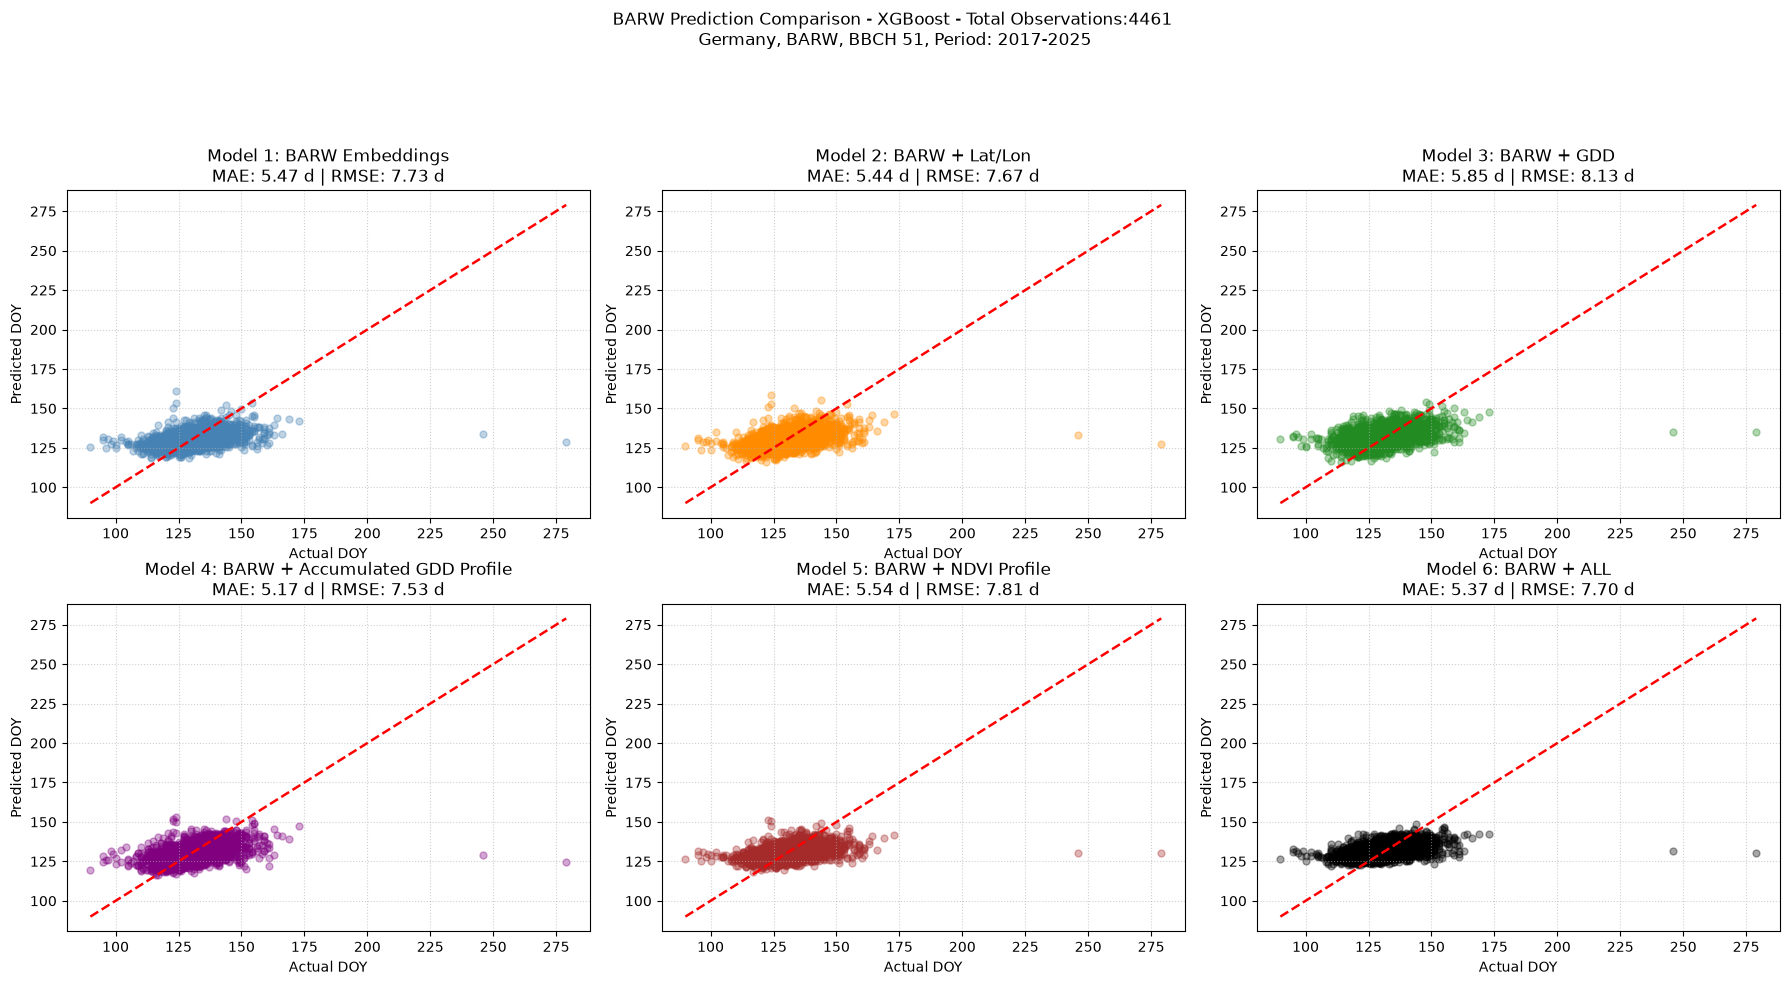

In [ ]:
df_folds = pd.DataFrame(fold_results)

overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))
overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))
overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))
overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))
overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))
overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))

# Print overall results
print(f"\n{'='*80}")
print(f"OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) ({selected_folder.name})")
print(f"{'='*80}")
print(f"Model 1: {model} Embeddings --> Overall MAE:  {overall_m1_mae:.2f} days | Overall RMSE: {overall_m1_rmse:.2f} days")
print(f"Model 2: {model} + (Latitude, Longitude) --> Overall MAE:  {overall_m2_mae:.2f} days | Overall RMSE: {overall_m2_rmse:.2f} days")
print(f"Model 3: {model} + GDD --> Overall MAE:  {overall_m3_mae:.2f} days | Overall RMSE: {overall_m3_rmse:.2f} days")
print(f"Model 4: {model} + Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  {overall_m4_mae:.2f} days | Overall RMSE: {overall_m4_rmse:.2f} days")
print(f"Model 5: {model} + NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  {overall_m5_mae:.2f} days | Overall RMSE: {overall_m5_rmse:.2f} days")
print(f"Model 6: {model} + ALL --> Overall MAE:  {overall_m6_mae:.2f} days | Overall RMSE: {overall_m6_rmse:.2f} days")

display(df_folds)

results_path_filtered = summary_save_path / f"{model.lower()}_loyocv_results_xgboost.csv"
df_folds.to_csv(results_path_filtered, sep=";", index=False)

# Scatter plots for the models
plt.figure(figsize=(18, 10))

models_plot = [
    (f"Model 1: {model} Embeddings", m1_preds, overall_m1_mae, overall_m1_rmse, "steelblue"),
    (f"Model 2: {model} + Lat/Lon", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + GDD", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + Accumulated GDD Profile", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + NDVI Profile", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL", m6_preds, overall_m6_mae, overall_m6_rmse, "black")]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(2, 3, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
    plt.plot([min(actual_doy), max(actual_doy)], [min(actual_doy), max(actual_doy)], "r--", lw=1.8, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
    plt.xlabel("Actual DOY")
    plt.ylabel("Predicted DOY")
    plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.suptitle(f"{model} Prediction Comparison - XGBoost - Total Observations:{len(df_clean)} \n{final_name}")
# Save plot
plt.savefig(summary_save_path / f"{model.lower()}_scatter_comparison_xgboost", dpi=300, bbox_inches="tight")
plt.show()

# Compress the features and do predictions again

Create a fresh dataframe to use

In [30]:
# dataframe to use 
df_reduced = pd.DataFrame()

# Get the basic columns of the df_final
df_reduced["Year"] = df_clean["Year"].astype(int)
df_reduced["Latitude"] = df_clean["Latitude"]
df_reduced["Longitude"] = df_clean["Longitude"]
df_reduced["DOY"] = df_clean["DOY"]

# Get TESSERA embeddings
for col in embedding_cols:
    df_reduced[col] = df_clean[col]


Feature reduction for GDD 

In [31]:
# We compress 365 noisy daily columns into 12 monthly thermal integrals that
# represent discrete developmental phases (winter dormancy, spring resumption,
# summer maturation, and autumn harvest), plus chilling and heat-stress indicators.
gdd_cols = [c for c in df_clean.columns if c.startswith("GDD_doy_")]
if gdd_cols:
    gdd_mat = df_clean[gdd_cols].values  # Shape: (N, 365)

    # 1.1 Monthly Thermal Integrals (January to December)
    # Each slice sums the thermal energy accrued specifically within that 30/31-day calendar block.
    # Jan (1-31), Feb (32-59), Mar (60-90), Apr (91-120), May (121-151), Jun (152-181),
    # Jul (182-212), Aug (213-243), Sep (244-273), Oct (274-304), Nov (305-334), Dec (335-365).
    month_slices = {
        "Jan": (0, 31),
        "Feb": (31, 59),
        "Mar": (59, 90),
        "Apr": (90, 120),
        "May": (120, 151),
        "Jun": (151, 181),
        "Jul": (181, 212),
        "Aug": (212, 243),
        "Sep": (243, 273),
        "Oct": (273, 304),
        "Nov": (304, 334),
        "Dec": (334, 365),
    }

    for month_name, (start_idx, end_idx) in month_slices.items():
        # Captures monthly heat velocity without forcing the tree to learn cross-column additions
        df_reduced[f"GDD_sum_{month_name}"] = gdd_mat[:, start_idx:end_idx].sum(axis=1)

    # 1.2 Dormancy Pause / Cold Delay Days (DOY 1 to 120: Jan 1 - Apr 30)
    # Counts days where GDD <= 0.5°C (mean temp <= base temp), directly capturing
    # winter chilling severity and early-season developmental stalls.
    df_reduced["GDD_cold_days_winter_spring"] = (gdd_mat[:, 0:120] <= 0.5).sum(axis=1)

    # 1.3 Summer Heat Concentration (DOY 152 to 243: Jun 1 - Aug 31)
    # Measures the magnitude of peak summer thermal forcing during grain/tuber filling.
    df_reduced["GDD_sum_summer_peak"] = gdd_mat[:, 151:243].sum(axis=1)

Feature reduction for AGDD

In [32]:
# Sampling at a fixed 14-day
agdd_checkpoints_doy = [
    14, 28, 42, 56, 70, 84, 98, 112, 126, 140, 154, 168, 182,
    196, 210, 224, 238, 252, 266, 280, 294, 308, 322, 336, 350, 365
]

for doy_val in agdd_checkpoints_doy:
    col_name = f"AGDD_doy_{doy_val}"
    if col_name in df_clean.columns:
        # Pre-computed cumulative heat sum allows trees to evaluate milestone completion at a single split
        df_reduced[f"AGDD_biweekly_doy_{doy_val}"] = df_clean[col_name]

# Spring accumulation acceleration (DOY 60 to DOY 154: early March to early June)
# Captures the slope of spring warming (fast warm spring vs. prolonged cold spring)
if "AGDD_doy_154" in df_clean.columns and "AGDD_doy_60" in df_clean.columns:
    df_reduced["AGDD_spring_velocity"] = df_clean["AGDD_doy_154"] - df_clean["AGDD_doy_60"]

C:\Users\jimpa\AppData\Local\Temp\ipykernel_13568\2886798994.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[f"AGDD_biweekly_doy_{doy_val}"] = df_clean[col_name]
C:\Users\jimpa\AppData\Local\Temp\ipykernel_13568\2886798994.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[f"AGDD_biweekly_doy_{doy_val}"] = df_clean[col_name]
C:\Users\jimpa\AppData\Local\Temp\ipykernel_13568\2886798994.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

Feature reduction for NDVI

In [33]:
# We extract: (a) 5 core Land Surface Phenology (LSP) curve parameters, and
# (b) 26 bi-weekly Accumulated NDVI (ANDVI) checkpoints representing cumulative biomass.
ndvi_cols = [c for c in df_clean.columns if c.startswith("NDVI_doy_")]
if ndvi_cols:
    ndvi_mat = df_clean[ndvi_cols].values  # Shape: (N, 365)

    # 3.1 Winter/Soil Baseline Reflectance (DOY 1 to 75)
    # Captures un-vegetated background soil and residue reflectance
    df_reduced["NDVI_base"] = np.min(ndvi_mat[:, 0:75], axis=1)

    # 3.2 Peak Canopy Value and Timing (DOY 60 to 300)
    # The day of maximum NDVI is the primary optical anchor for heading, flowering, and peak biomass
    ndvi_growth_window = ndvi_mat[:, 59:300]
    df_reduced["NDVI_max"] = np.max(ndvi_growth_window, axis=1)
    df_reduced["NDVI_peak_doy"] = np.argmax(ndvi_growth_window, axis=1) + 60

    # 3.3 Seasonal Canopy Amplitude
    # Difference between maximum green canopy and bare ground (total seasonal leaf capacity)
    df_reduced["NDVI_amplitude"] = df_reduced["NDVI_max"] - df_reduced["NDVI_base"]

    # 3.4 Maximum Green-up Velocity (Slope)
    # The maximum 7-day rate of change during the spring green-up surge
    ndvi_7d_diff = ndvi_growth_window[:, 7:] - ndvi_growth_window[:, :-7]
    df_reduced["NDVI_max_greenup_slope"] = np.max(ndvi_7d_diff, axis=1) / 7.0

    # 3.5 Total Integrated Seasonal Vigor (AUC)
    # Integral of NDVI exceeding background soil reflectance (proxy for total absorbed radiation)
    df_reduced["NDVI_AUC_seasonal"] = np.sum(np.clip(ndvi_mat - 0.20, 0, None), axis=1)

    # 3.6 Accumulated NDVI (ANDVI) Across the Full Year (26 Bi-Weekly Checkpoints)
    # We integrate daily active canopy cover (excess over soil threshold 0.15)
    # and sample cumulative intercepted radiation at the exact same 14-day intervals as AGDD.
    andvi_daily_integral = np.cumsum(np.clip(ndvi_mat - 0.15, 0, None), axis=1)
    for doy_val in agdd_checkpoints_doy:
        # ANDVI acts as the cumulative biomass odometer for the tree models
        df_reduced[f"ANDVI_biweekly_doy_{doy_val}"] = andvi_daily_integral[:, doy_val - 1]

C:\Users\jimpa\AppData\Local\Temp\ipykernel_13568\55353598.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced["NDVI_base"] = np.min(ndvi_mat[:, 0:75], axis=1)
C:\Users\jimpa\AppData\Local\Temp\ipykernel_13568\55353598.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced["NDVI_max"] = np.max(ndvi_growth_window, axis=1)
C:\Users\jimpa\AppData\Local\Temp\ipykernel_13568\55353598.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which h

Define feature sets

In [34]:
# Create the different featur sets for the baselines 
features_m1_embedding_only = embedding_cols

features_m2_embedding_spatial = embedding_cols + ["Latitude", "Longitude"]

features_m3_embedding_GDD = embedding_cols + [
    c for c in df_reduced.columns if c.startswith("GDD_")
]

features_m4_embedding_AGDD = embedding_cols + [
    c for c in df_reduced.columns if c.startswith("AGDD_")
]

features_m5_embedding_NDVI = embedding_cols + [
    c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")
]

features_m6_embedding_all = embedding_cols + (
    ["Latitude", "Longitude"]
    + [c for c in df_reduced.columns if c.startswith("GDD_")]
    + [c for c in df_reduced.columns if c.startswith("AGDD_")]
    + [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")]
)

# Set up dictionary for the baseline feature sets
models_to_tune = {
    "M1": features_m1_embedding_only,
    "M2": features_m2_embedding_spatial,
    "M3": features_m3_embedding_GDD,
    "M4": features_m4_embedding_AGDD,
    "M5": features_m5_embedding_NDVI,
    "M6": features_m6_embedding_all,
}

y_all = df_reduced["DOY"]
groups_all = df_reduced["Year"]
logo = LeaveOneGroupOut()

best_params_dict = {}

# 2. HYPERPARAMETER SEARCH ACROSS EACH BASELINE
print("=" * 80)
print(f"RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (RANDOM FOREST - {model})")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_reduced[feat_cols]

    # Adjust max_features distribution based on feature count
    if len(feat_cols) <= 3:
        max_feat_dist = [1.0]
    else:
        max_feat_dist = uniform(0.25, 0.50)  # samples between 25% and 75% of features

    param_distributions = {
        "n_estimators": randint(150, 350),
        "max_depth": [None, 12, 18, 25],
        "min_samples_leaf": randint(1, 5),
        "min_samples_split": randint(2, 6),
        "max_features": max_feat_dist,
    }

    rf_search = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rf_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = rf_search.best_params_
    print(f" -> Best LOYOCV MAE: {-rf_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {rf_search.best_params_}")

print("=" * 75)
print("FEATURE REDUCTION SUMMARY")
print("=" * 75)
print(f"Total Observation Records:               {len(df_reduced)}")
print(f"Model 1 ({model} Only):                  {len(features_m1_embedding_only):3d} features")
print(f"Model 2 ({model} + Spatial):             {len(features_m2_embedding_spatial):3d} features")
print(f"Model 3 ({model} + GDD):                 {len(features_m3_embedding_GDD):3d} features")
print(f"Model 4 ({model} + AGDD):                {len(features_m4_embedding_AGDD):3d} features")
print(f"Model 5 ({model} + NDVI):                {len(features_m5_embedding_NDVI):3d} features")
print(f"Model 6 ({model} + All Features):        {len(features_m6_embedding_all):3d} features")
print("=" * 75)

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (RANDOM FOREST - ALPHAEARTH)

Tuning M1 (Total Features: 64)...
 -> Best LOYOCV MAE: 5.53 days
 -> Optimal Parameters: {'max_depth': None, 'max_features': np.float64(0.5123873301291946), 'min_samples_leaf': 3, 'min_samples_split': 3, 'n_estimators': 337}

Tuning M2 (Total Features: 66)...
 -> Best LOYOCV MAE: 5.53 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.4132703844029177), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M3 (Total Features: 78)...
 -> Best LOYOCV MAE: 4.75 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.3424272277627635), 'min_samples_leaf': 3, 'min_samples_split': 3, 'n_estimators': 193}

Tuning M4 (Total Features: 91)...
 -> Best LOYOCV MAE: 5.23 days
 -> Optimal Parameters: {'max_depth': 18, 'max_features': np.float64(0.704660201039391), 'min_samples_leaf': 4, 'min_samples_split': 3, 'n_estimators': 253}

Tuning M5 (Total F

LOYOCV for the reduced features

In [35]:
# 5. EXECUTE LEAVE-ONE-YEAR-OUT CROSS-VALIDATION (LOYOCV) ON REDUCED FEATURES
unique_years = sorted(df_reduced["Year"].unique())

m1_preds, m2_preds, m3_preds, m4_preds, m5_preds, m6_preds = [], [], [], [], [], []
actual_doy = []
test_years_list = []
fold_results = []

print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
  train_mask = df_reduced["Year"] != test_year
  test_mask = df_reduced["Year"] == test_year

  y_train = df_reduced.loc[train_mask, "DOY"]
  y_test = df_reduced.loc[test_mask, "DOY"]

  # ---------------------------------------------------------
  # 1. Fit Model 1: TESSERA Only
  # ---------------------------------------------------------
  rf_m1 = RandomForestRegressor(
    **best_params_dict["M1"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m1.fit(df_reduced.loc[train_mask, features_m1_embedding_only], y_train)
  pred_m1 = rf_m1.predict(df_reduced.loc[test_mask, features_m1_embedding_only])

  # ---------------------------------------------------------
  # 2. Fit Model 2: TESSERA + Spatial
  # ---------------------------------------------------------
  rf_m2 = RandomForestRegressor(
    **best_params_dict["M2"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m2.fit(df_reduced.loc[train_mask, features_m2_embedding_spatial], y_train)
  pred_m2 = rf_m2.predict(df_reduced.loc[test_mask, features_m2_embedding_spatial])

  # ---------------------------------------------------------
  # 3. Fit Model 3: TESSERA + GDD 
  # ---------------------------------------------------------
  rf_m3 = RandomForestRegressor(
    **best_params_dict["M3"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m3.fit(df_reduced.loc[train_mask, features_m3_embedding_GDD], y_train)
  pred_m3 = rf_m3.predict(df_reduced.loc[test_mask, features_m3_embedding_GDD])

  # ---------------------------------------------------------
  # 4. Fit Model 4: TESSERA + AGDD 
  # ---------------------------------------------------------
  rf_m4 = RandomForestRegressor(
    **best_params_dict["M4"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m4.fit(df_reduced.loc[train_mask, features_m4_embedding_AGDD], y_train)
  pred_m4 = rf_m4.predict(df_reduced.loc[test_mask, features_m4_embedding_AGDD])

  # ---------------------------------------------------------
  # 5. Fit Model 5: TESSERA + NDVI 
  # ---------------------------------------------------------
  rf_m5 = RandomForestRegressor(
    **best_params_dict["M5"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m5.fit(df_reduced.loc[train_mask, features_m5_embedding_NDVI], y_train)
  pred_m5 = rf_m5.predict(df_reduced.loc[test_mask, features_m5_embedding_NDVI])

  # ---------------------------------------------------------
  # 6. Fit Model 6: TESSERA + ALL
  # ---------------------------------------------------------
  rf_m6 = RandomForestRegressor(
    **best_params_dict["M6"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m6.fit(df_reduced.loc[train_mask, features_m6_embedding_all], y_train)
  pred_m6 = rf_m6.predict(df_reduced.loc[test_mask, features_m6_embedding_all])

  # Compute fold-level metrics
  mae_m1 = mean_absolute_error(y_test, pred_m1)
  rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

  mae_m2 = mean_absolute_error(y_test, pred_m2)
  rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

  mae_m3 = mean_absolute_error(y_test, pred_m3)
  rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

  mae_m4 = mean_absolute_error(y_test, pred_m4)
  rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

  mae_m5 = mean_absolute_error(y_test, pred_m5)
  rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

  mae_m6 = mean_absolute_error(y_test, pred_m6)
  rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

  fold_results.append({
      "Test_Year": test_year,
      "N_Samples": len(y_test),
      f"M1_{model}_Only_MAE": round(mae_m1, 2),
      f"M1_{model}_Only_RMSE": round(rmse_m1, 2),
      f"M2_{model}_Spatial_MAE": round(mae_m2, 2),
      f"M2_{model}_Spatial_RMSE": round(rmse_m2, 2),
      f"M3_{model}_GDD_MAE": round(mae_m3, 2),
      f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
      f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
      f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
      f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
      f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
      f"M6_{model}_All_MAE": round(mae_m6, 2),
      f"M6_{model}_All_RMSE": round(rmse_m6, 2),

  })

  m1_preds.extend(pred_m1)
  m2_preds.extend(pred_m2)
  m3_preds.extend(pred_m3)
  m4_preds.extend(pred_m4)
  m5_preds.extend(pred_m5)
  m6_preds.extend(pred_m6)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
      f"Year {test_year} (N={len(y_test):3d}) | "
      f"{model} Only MAE: {mae_m1:5.2f}d | "
      f"{model}+Spatial MAE: {mae_m2:5.2f}d | "
      f"Fusion ({model}+Reduced 12M GDD + Stress) MAE: {mae_m3:5.2f}d"
      f"Fusion ({model}+Reduced 26-Step AGDD) MAE: {mae_m4:5.2f}d"
      f"Fusion ({model}+Reduced NDVI LSP + ANDVI) MAE: {mae_m5:5.2f}d"
      f"Fusion ({model}+Reduced Combined Multimodal) MAE: {mae_m6:5.2f}d"
  )

print("\nLOYOCV execution finished!")

Starting LOYOCV across 8 folds...

Year 2017 (N=621) | ALPHAEARTH Only MAE:  4.41d | ALPHAEARTH+Spatial MAE:  4.37d | Fusion (ALPHAEARTH+Reduced 12M GDD + Stress) MAE:  3.86dFusion (ALPHAEARTH+Reduced 26-Step AGDD) MAE:  5.30dFusion (ALPHAEARTH+Reduced NDVI LSP + ANDVI) MAE:  4.49dFusion (ALPHAEARTH+Reduced Combined Multimodal) MAE:  4.07d
Year 2018 (N=598) | ALPHAEARTH Only MAE:  4.57d | ALPHAEARTH+Spatial MAE:  4.56d | Fusion (ALPHAEARTH+Reduced 12M GDD + Stress) MAE:  4.21dFusion (ALPHAEARTH+Reduced 26-Step AGDD) MAE:  4.20dFusion (ALPHAEARTH+Reduced NDVI LSP + ANDVI) MAE:  4.54dFusion (ALPHAEARTH+Reduced Combined Multimodal) MAE:  4.32d
Year 2019 (N=592) | ALPHAEARTH Only MAE:  5.82d | ALPHAEARTH+Spatial MAE:  5.81d | Fusion (ALPHAEARTH+Reduced 12M GDD + Stress) MAE:  5.70dFusion (ALPHAEARTH+Reduced 26-Step AGDD) MAE:  6.12dFusion (ALPHAEARTH+Reduced NDVI LSP + ANDVI) MAE:  5.88dFusion (ALPHAEARTH+Reduced Combined Multimodal) MAE:  5.70d
Year 2020 (N=579) | ALPHAEARTH Only MAE:  6.

Print & Save results

In [36]:
results_dir = Path("Results")
results_dir.mkdir(parents=True, exist_ok=True)

df_folds = pd.DataFrame(fold_results)

# Micro-averaged pooled metrics across all 584 observations
overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))

overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))

overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))

overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))

overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))

overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))
print("=" * 85)
print(f"OVERALL LOYOCV BENCHMARK: {model} EMBEDDINGS + BASELINE DATA")
print(
    f"Model 1: {model} Only                        --> MAE: {overall_m1_mae:5.2f} d |"
    f" RMSE: {overall_m1_rmse:5.2f} d"
)
print(
    f"Model 2: {model} + Spatial (Lat, Lon)               --> MAE: {overall_m2_mae:5.2f} d |"
    f" RMSE: {overall_m2_rmse:5.2f} d"
)
print(
    f"Model 3: {model} + Reduced 12M GDD + Stress Fusion  --> MAE: {overall_m3_mae:5.2f} d |"
    f" RMSE: {overall_m3_rmse:5.2f} d"
)
print(
    f"Model 4: {model} + Reduced 26-Step AGDD Fusion      --> MAE: {overall_m4_mae:5.2f} d |"
    f" RMSE: {overall_m4_rmse:5.2f} d"
)
print(
    f"Model 5: {model} + Reduced NDVI Fusion              --> MAE: {overall_m5_mae:5.2f} d |"
    f" RMSE: {overall_m5_rmse:5.2f} d"
)
print(
    f"Model 6: {model} + Reduced Combined Multimodal      --> MAE: {overall_m6_mae:5.2f} d |"
    f" RMSE: {overall_m6_rmse:5.2f} d"
)
print("-" * 85)

display(df_folds)

# -------------------------------------------------------------
# Save Results to CSV
# -------------------------------------------------------------
summary = ( summary_save_path/
    f"{model.lower()}_loyocv_summary_rf_reduced.csv"
)
df_folds.to_csv(summary, sep=";", index=False)
print(f"\nFold-level summary saved to: {summary_save_path.resolve()}")

OVERALL LOYOCV BENCHMARK: ALPHAEARTH EMBEDDINGS + BASELINE DATA
Model 1: ALPHAEARTH Only                        --> MAE:  5.49 d | RMSE:  7.76 d
Model 2: ALPHAEARTH + Spatial (Lat, Lon)               --> MAE:  5.50 d | RMSE:  7.77 d
Model 3: ALPHAEARTH + Reduced 12M GDD + Stress Fusion  --> MAE:  4.74 d | RMSE:  7.14 d
Model 4: ALPHAEARTH + Reduced 26-Step AGDD Fusion      --> MAE:  5.24 d | RMSE:  7.61 d
Model 5: ALPHAEARTH + Reduced NDVI Fusion              --> MAE:  5.55 d | RMSE:  7.83 d
Model 6: ALPHAEARTH + Reduced Combined Multimodal      --> MAE:  4.84 d | RMSE:  7.24 d
-------------------------------------------------------------------------------------


,Test_Year,N_Samples,M1_ALPHAEARTH_Only_MAE,M1_ALPHAEARTH_Only_RMSE,M2_ALPHAEARTH_Spatial_MAE,M2_ALPHAEARTH_Spatial_RMSE,M3_ALPHAEARTH_GDD_MAE,M3_ALPHAEARTH_GDD_RMSE,M4_ALPHAEARTH_AGDD_MAE,M4_ALPHAEARTH_AGDD_RMSE,M5_ALPHAEARTH_NDVI_MAE,M5_ALPHAEARTH_NDVI_RMSE,M6_ALPHAEARTH_All_MAE,M6_ALPHAEARTH_All_RMSE
0,2017,621,4.41,5.97,4.37,5.93,3.86,5.44,5.30,6.91,4.49,6.05,4.07,5.70
1,2018,598,4.57,6.16,4.56,6.13,4.21,5.86,4.20,5.78,4.54,6.13,4.32,6.01
2,2019,592,5.82,7.63,5.81,7.62,5.70,7.63,6.12,7.88,5.88,7.69,5.70,7.60
3,2020,579,6.43,8.02,6.49,8.12,5.75,7.40,6.52,8.04,6.52,8.18,5.98,7.58
4,2021,543,6.90,8.69,6.99,8.75,4.65,6.57,4.74,6.60,7.12,8.89,4.78,6.56
5,2022,529,4.13,5.78,4.05,5.72,4.17,5.79,4.31,5.94,4.09,5.73,4.20,5.82
6,2023,511,4.83,6.69,4.80,6.74,4.02,5.64,4.60,6.34,4.83,6.77,3.96,5.68
7,2024,488,7.13,12.01,7.15,12.03,5.62,11.56,6.06,12.11,7.17,12.02,5.73,11.71



Fold-level summary saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_ALPHAEARTH


Scatter plots

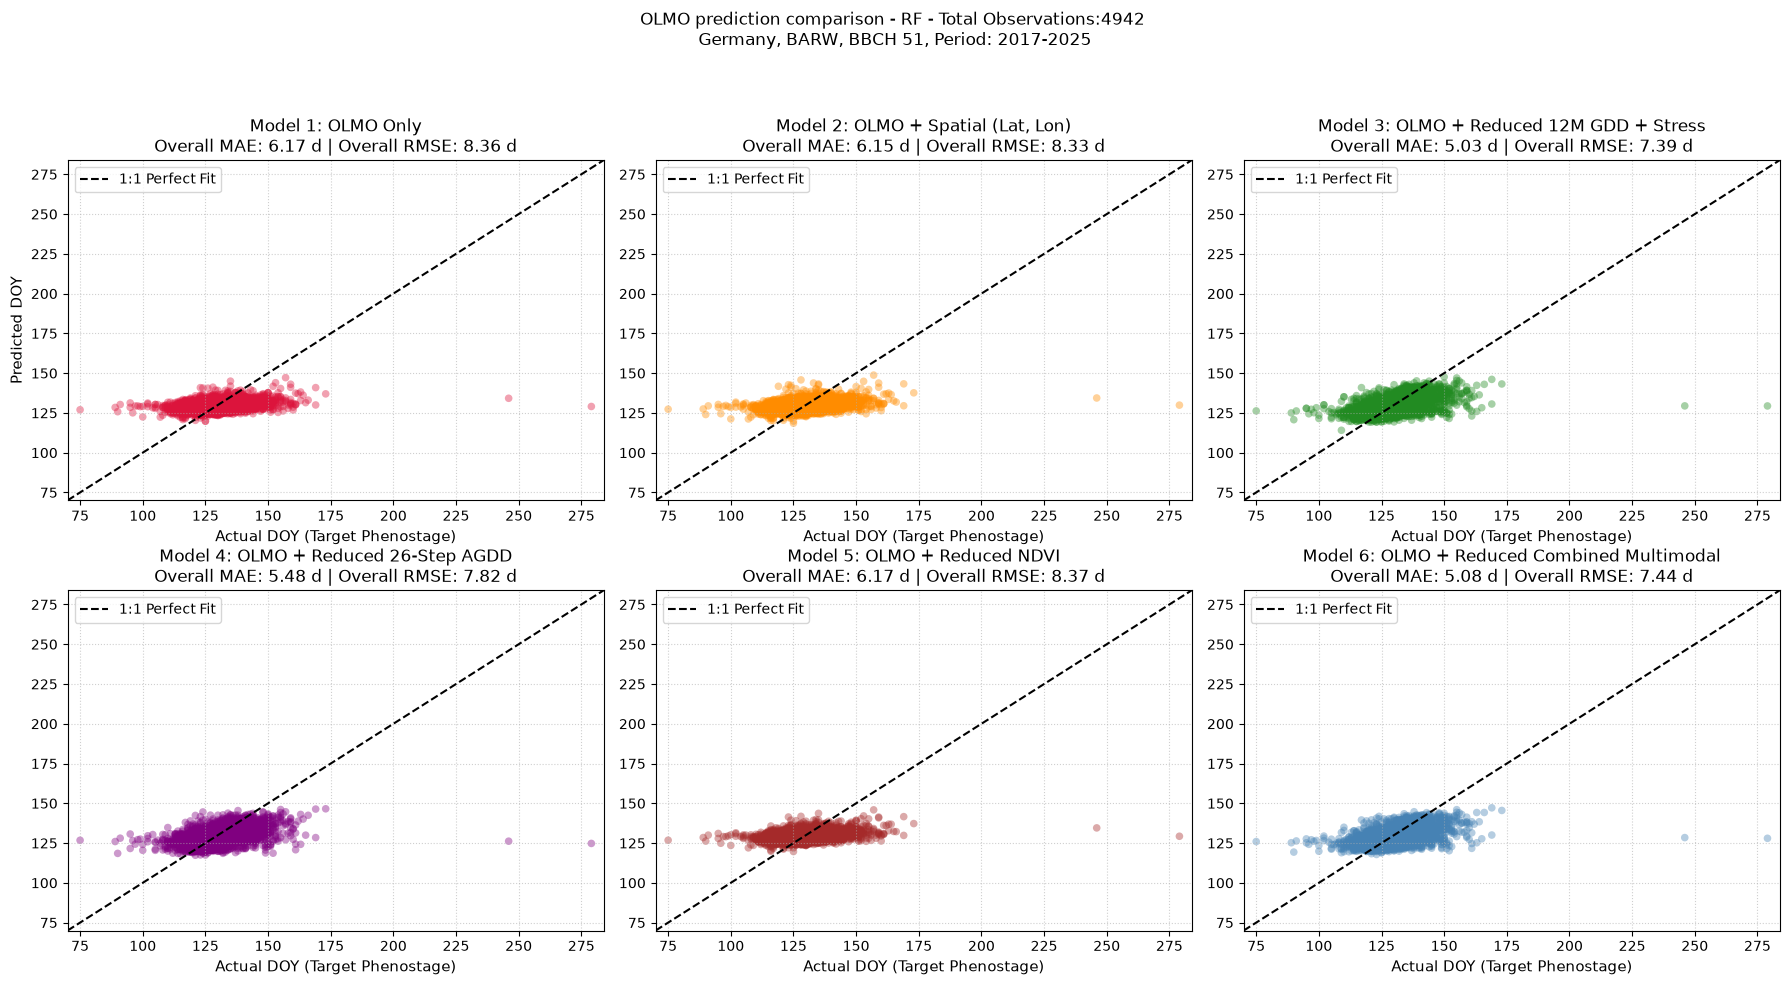

In [11]:
plt.figure(figsize=(18, 10))
model_configs = [
    (f"Model 1: {model} Only", m1_preds, overall_m1_mae, overall_m1_rmse, "crimson"),
    (f"Model 2: {model} + Spatial (Lat, Lon)", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + Reduced 12M GDD + Stress", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + Reduced 26-Step AGDD", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + Reduced NDVI", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + Reduced Combined Multimodal", m6_preds, overall_m6_mae, overall_m6_rmse, "steelblue"),
]

min_val = min(actual_doy) - 5
max_val = max(actual_doy) + 5

for idx, (title, preds, mae_val, rmse_val, color) in enumerate(model_configs, start=1):
    plt.subplot(2, 3, idx)
    plt.scatter(actual_doy, preds, alpha=0.4, color=color, edgecolors="none", s=30)
    plt.plot([min_val, max_val], [min_val, max_val], "k--", lw=1.5, label="1:1 Perfect Fit")
    
    plt.title(f"{title}\nOverall MAE: {mae_val:.2f} d | Overall RMSE: {rmse_val:.2f} d", fontsize=12)
    plt.xlabel("Actual DOY (Target Phenostage)", fontsize=11)
    if idx == 1:
        plt.ylabel("Predicted DOY", fontsize=11)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.suptitle(f"{model} prediction comparison - RF - Total Observations:{len(df_clean)} \n{final_name}")
plt.subplots_adjust(top=0.83)
plt.savefig(summary_save_path / f"scatter_comparison_{model.lower()}_rf_reduced.png", dpi=300)
plt.show()

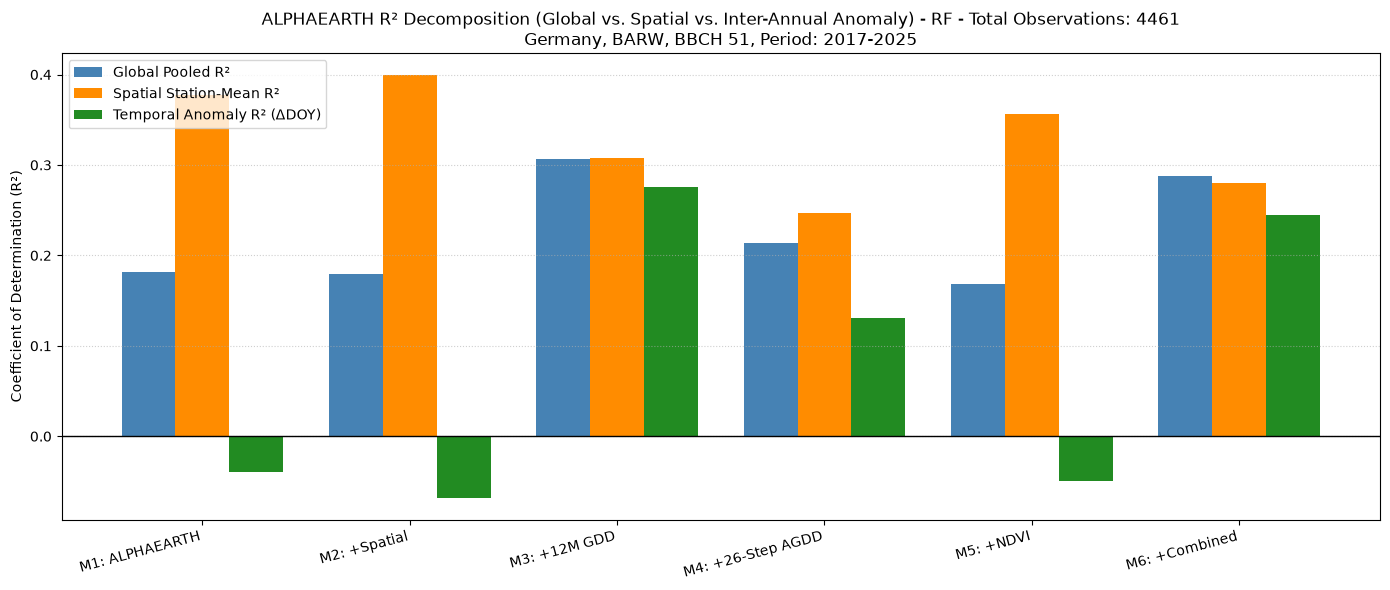

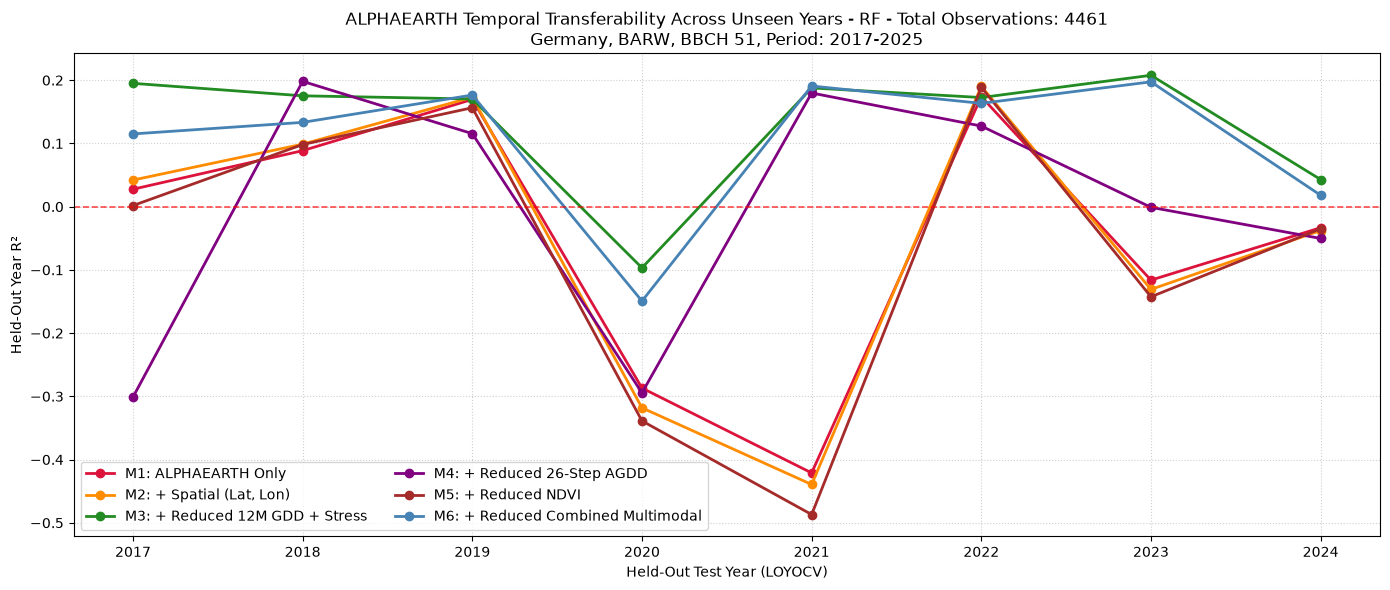

In [37]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_clean to separate spatial vs. temporal variance
if "PEP_ID" in df_clean.columns:
  station_ids = df_clean["PEP_ID"].values
else:
  station_ids = (
      df_clean["Latitude"].round(4).astype(str)
      + "_"
      + df_clean["Longitude"].round(4).astype(str)
  ).values

years_arr = df_clean["Year"].astype(int).values

# Match your exact RF reduced prediction variables, titles, and colors
rf_reduced_models = [
    (f"M1: {model} Only", np.asarray(m1_preds), "crimson"),
    ("M2: + Spatial (Lat, Lon)", np.asarray(m2_preds), "darkorange"),
    ("M3: + Reduced 12M GDD + Stress", np.asarray(m3_preds), "forestgreen"),
    ("M4: + Reduced 26-Step AGDD", np.asarray(m4_preds), "purple"),
    ("M5: + Reduced NDVI", np.asarray(m5_preds), "brown"),
    (
        "M6: + Reduced Combined Multimodal",
        np.asarray(m6_preds),
        "steelblue",
    ),
]

# -------------------------------------------------------------------------
# 1. R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (RF)
# -------------------------------------------------------------------------
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    f"M1: {model}",
    "M2: +Spatial",
    "M3: +12M GDD",
    "M4: +26-Step AGDD",
    "M5: +NDVI",
    "M6: +Combined",
]

for _, preds, _ in rf_reduced_models:
  # 1. Global Pooled R²
  g_r2 = r2_score(actual_doy_arr, preds)

  # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
  df_tmp = pd.DataFrame({
      "Station": station_ids,
      "Actual": actual_doy_arr,
      "Pred": preds,
  })
  st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
  s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

  df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
  obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
  pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
  t_r2 = r2_score(obs_anom, pred_anom)

  global_r2_list.append(g_r2)
  spatial_r2_list.append(s_r2)
  temporal_r2_list.append(t_r2)

x_pos = np.arange(len(rf_reduced_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R² (ΔDOY)",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) -"
    f" RF - Total Observations: {len(df_clean)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_decomposition_{model.lower()}_rf_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -------------------------------------------------------------------------
# 2. Per-Year LOYOCV R² Trajectory Across Held-Out Years (RF Reduced)
# -------------------------------------------------------------------------
unique_years = sorted(np.unique(years_arr))

plt.figure(figsize=(14, 6))

for m_label, preds, color in rf_reduced_models:
  yearly_r2 = []
  for yr in unique_years:
    mask = years_arr == yr
    yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

  plt.plot(
      unique_years,
      yearly_r2,
      marker="o",
      lw=2,
      color=color,
      label=m_label,
  )

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"{model} Temporal Transferability Across Unseen Years - RF - Total"
    f" Observations: {len(df_clean)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_per_year_{model.lower()}_rf_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Do the same predictions with reduced features using XGBoost

Initiate GridSearch

In [38]:
# Hyperparameter search space for XGBoost models
print("=" * 80)
print("RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (XGBOOST)")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_reduced[feat_cols]

    # Adapt feature subsampling ratio to feature space size
    if len(feat_cols) <= 3:
        colsample_dist = [1.0]
    else:
        colsample_dist = uniform(0.30, 0.50)  # Randomly samples between 30% and 80%

    xgb_param_distributions = {
        # Ensemble size and shrinkage
        "n_estimators": randint(150, 350),
        "learning_rate": uniform(0.02, 0.08),  # Range: 0.02 to 0.10
        # Tree architecture (keep shallow for small N)
        "max_depth": randint(3, 6),            # Depths 3, 4, 5
        "min_child_weight": randint(2, 7),     # Analogous to min_samples_leaf (2 to 6)
        "gamma": uniform(0.0, 1.5),            # Minimum loss reduction for a split
        # Stochastic sampling
        "subsample": uniform(0.65, 0.30),      # Row subsampling (0.65 to 0.95)
        "colsample_bytree": colsample_dist,    # Column subsampling
        # Regularization
        "reg_alpha": [0.0, 0.1, 1.0],
        "reg_lambda": [1.0, 3.0, 8.0],
    }

    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(
            objective="reg:squarederror",
            eval_metric="mae",
            random_state=42,
            n_jobs=1,  # Keep inner booster single-threaded
        ),
        param_distributions=xgb_param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,  # Parallelize across CV folds/iterations
        verbose=0,
    )

    # Fit using groups to enforce Leave-One-Year-Out validation
    xgb_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = xgb_search.best_params_
    print(f" -> Best LOYOCV MAE: {-xgb_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {xgb_search.best_params_}")

# Prediction lists for pooled evaluation
m1_preds = []
m2_preds = []
m3_preds = []
m4_preds = []
m5_preds = []
m6_preds = []
actual_doy = []
test_years_list = []
fold_results = []

print(
    f"Model 1 ({model} Only):        "
    f" {len(features_m1_embedding_only)} features"
)
print(
    f"Model 2 ({model} + Spatial):   "
    f" {len(features_m2_embedding_spatial)} features"
)
print(
    f"Model 3 ({model} + GDD ):      "
    f" {len(features_m3_embedding_GDD)} features"
)
print(
    f"Model 4 ({model} + AGDD):      "
    f" {len(features_m4_embedding_AGDD)} features"
)
print(
    f"Model 5 ({model} + NDVI):     "
    f" {len(features_m5_embedding_NDVI)} features"
)
print(
    f"Model 6 ({model} + ALL):      "
    f" {len(features_m6_embedding_all)} features"
)
print(f"Total LOYOCV folds:            {len(unique_years)} years")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (XGBOOST)

Tuning M1 (Total Features: 64)...
 -> Best LOYOCV MAE: 5.48 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.5051914615178148), 'gamma': np.float64(1.133326707814573), 'learning_rate': np.float64(0.0383038532393298), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 235, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'subsample': np.float64(0.8924361138693251)}

Tuning M2 (Total Features: 66)...
 -> Best LOYOCV MAE: 5.45 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.6566223936114974), 'gamma': np.float64(1.1411775729253462), 'learning_rate': np.float64(0.0649021758055597), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 286, 'reg_alpha': 1.0, 'reg_lambda': 8.0, 'subsample': np.float64(0.6832672462435494)}

Tuning M3 (Total Features: 78)...
 -> Best LOYOCV MAE: 4.75 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.7541329429833268), 'gamma': np.float64(0.35934283600045863), '

Run LOYOCV 

In [39]:
print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
    train_mask = df_reduced["Year"] != test_year
    test_mask = df_reduced["Year"] == test_year
    y_train = df_reduced.loc[train_mask, "DOY"]
    y_test = df_reduced.loc[test_mask, "DOY"]

    # --- Model 1: TESSERA only ---
    xgb_m1 = XGBRegressor(
        **best_params_dict["M1"], random_state=42, n_jobs=-1
    )
    xgb_m1.fit(
        df_reduced.loc[train_mask, features_m1_embedding_only], y_train
    )
    pred_m1 = xgb_m1.predict(
        df_reduced.loc[test_mask, features_m1_embedding_only]
    )

    # --- Model 2: TESSERA & Lat/Lon ---
    xgb_m2 = XGBRegressor(
        **best_params_dict["M2"], random_state=42, n_jobs=-1
    )
    xgb_m2.fit(
        df_reduced.loc[train_mask, features_m2_embedding_spatial], y_train
    )
    pred_m2 = xgb_m2.predict(
        df_reduced.loc[test_mask, features_m2_embedding_spatial]
    )

    # --- Model 3: TESSERA & GDD ---
    xgb_m3 = XGBRegressor(
        **best_params_dict["M3"], random_state=42, n_jobs=-1
    )
    xgb_m3.fit(
        df_reduced.loc[train_mask, features_m3_embedding_GDD], y_train
    )
    pred_m3 = xgb_m3.predict(
        df_reduced.loc[test_mask, features_m3_embedding_GDD]
    )

    # --- Model 4: TESSERA & AGDD ---
    xgb_m4 = XGBRegressor(
        **best_params_dict["M4"], random_state=42, n_jobs=-1
    )
    xgb_m4.fit(
        df_reduced.loc[train_mask, features_m4_embedding_AGDD], y_train
    )
    pred_m4 = xgb_m4.predict(
        df_reduced.loc[test_mask, features_m4_embedding_AGDD]
    )

    # --- Model 5: Combined Multimodal ---
    xgb_m5 = XGBRegressor(
        **best_params_dict["M5"], random_state=42, n_jobs=-1
    )
    xgb_m5.fit(
        df_reduced.loc[train_mask, features_m5_embedding_NDVI], y_train
    )
    pred_m5 = xgb_m5.predict(
        df_reduced.loc[test_mask, features_m5_embedding_NDVI]
    )

    # --- Model 6: Combined Multimodal ---
    xgb_m6 = XGBRegressor(
        **best_params_dict["M6"], random_state=42, n_jobs=-1  
    )
    xgb_m6.fit(
        df_reduced.loc[train_mask, features_m6_embedding_all], y_train
        )
    pred_m6 = xgb_m6.predict(
        df_reduced.loc[test_mask, features_m6_embedding_all]
    )
    
    # Fold metrics
    mae_m1 = mean_absolute_error(y_test, pred_m1)
    rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

    mae_m2 = mean_absolute_error(y_test, pred_m2)
    rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

    mae_m3 = mean_absolute_error(y_test, pred_m3)
    rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

    mae_m4 = mean_absolute_error(y_test, pred_m4)
    rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

    mae_m5 = mean_absolute_error(y_test, pred_m5)
    rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

    mae_m6 = mean_absolute_error(y_test, pred_m6)
    rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

    fold_results.append(
    {
        "Test_Year": test_year,
        "N_Samples": len(y_test),
        f"M1_{model}_MAE": round(mae_m1, 2),
        f"M1_{model}_RMSE": round(rmse_m1, 2),
        f"M2_{model}_LatLon_MAE": round(mae_m2, 2),
        f"M2_{model}_LatLon_RMSE": round(rmse_m2, 2),
        f"M3_{model}_GDD_MAE": round(mae_m3, 2),
        f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
        f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
        f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
        f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
        f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
        f"M6_{model}_Combined_MAE": round(mae_m6, 2),
        f"M6_{model}_Combined_RMSE": round(rmse_m6, 2),
    }
    )

    m1_preds.extend(pred_m1)
    m2_preds.extend(pred_m2)
    m3_preds.extend(pred_m3)
    m4_preds.extend(pred_m4)
    m5_preds.extend(pred_m5)
    m6_preds.extend(pred_m6)
    actual_doy.extend(y_test.values)
    test_years_list.extend([test_year] * len(y_test))

    print(
        f"Year {test_year} (N={len(y_test):3d}) "
        f"M1 ({model}) MAE: {mae_m1:5.2f} d "
        f"M2 ({model} + Lat/Lon) MAE: {mae_m2:5.2f} d "
        f"M3 ({model} + GDD) MAE: {mae_m3:5.2f} d "
        f"M4 ({model} + AGDD) MAE: {mae_m4:5.2f} d "
        f"M5 ({model} + NDVI) MAE: {mae_m5:5.2f} d "
        f"M6 Combined MAE: {mae_m6:5.2f} d "
    )

print("\nLOYOCV evaluation finished!")


Starting LOYOCV across 8 folds...

Year 2017 (N=621) M1 (ALPHAEARTH) MAE:  4.41 d M2 (ALPHAEARTH + Lat/Lon) MAE:  4.44 d M3 (ALPHAEARTH + GDD) MAE:  4.32 d M4 (ALPHAEARTH + AGDD) MAE:  5.09 d M5 (ALPHAEARTH + NDVI) MAE:  4.53 d M6 Combined MAE:  4.45 d 
Year 2018 (N=598) M1 (ALPHAEARTH) MAE:  4.62 d M2 (ALPHAEARTH + Lat/Lon) MAE:  4.57 d M3 (ALPHAEARTH + GDD) MAE:  4.66 d M4 (ALPHAEARTH + AGDD) MAE:  4.27 d M5 (ALPHAEARTH + NDVI) MAE:  4.67 d M6 Combined MAE:  4.29 d 
Year 2019 (N=592) M1 (ALPHAEARTH) MAE:  5.87 d M2 (ALPHAEARTH + Lat/Lon) MAE:  5.71 d M3 (ALPHAEARTH + GDD) MAE:  5.61 d M4 (ALPHAEARTH + AGDD) MAE:  5.92 d M5 (ALPHAEARTH + NDVI) MAE:  5.81 d M6 Combined MAE:  5.46 d 
Year 2020 (N=579) M1 (ALPHAEARTH) MAE:  6.31 d M2 (ALPHAEARTH + Lat/Lon) MAE:  6.23 d M3 (ALPHAEARTH + GDD) MAE:  5.23 d M4 (ALPHAEARTH + AGDD) MAE:  6.38 d M5 (ALPHAEARTH + NDVI) MAE:  6.20 d M6 Combined MAE:  5.40 d 
Year 2021 (N=543) M1 (ALPHAEARTH) MAE:  6.46 d M2 (ALPHAEARTH + Lat/Lon) MAE:  6.52 d M3 

Append, print results and create scatter plots


OVERALL LOYOCV BENCHMARK RESULTS (germany_barw_bbch51_2017-01-01_2025-12-31)
Model 1: ALPHAEARTH --> Overall MAE:  5.47 days | Overall RMSE: 7.73 days
Model 2: ALPHAEARTH + Spatial (Lat, Lon) --> Overall MAE:  5.47 days | Overall RMSE: 7.70 days
Model 3: ALPHAEARTH + Reduced 12M GDD + Stress Fusion --> Overall MAE:  4.73 days | Overall RMSE: 7.15 days
Model 4: ALPHAEARTH + Reduced 26-Step AGDD Fusion --> Overall MAE:  5.13 days | Overall RMSE: 7.51 days
Model 5: ALPHAEARTH + Reduced NDVI Fusion --> Overall MAE:  5.49 days | Overall RMSE: 7.75 days
Model 6: ALPHAEARTH + ALL --> Overall MAE:  4.70 days | Overall RMSE: 7.07 days


,Test_Year,N_Samples,M1_ALPHAEARTH_MAE,M1_ALPHAEARTH_RMSE,M2_ALPHAEARTH_LatLon_MAE,M2_ALPHAEARTH_LatLon_RMSE,M3_ALPHAEARTH_GDD_MAE,M3_ALPHAEARTH_GDD_RMSE,M4_ALPHAEARTH_AGDD_MAE,M4_ALPHAEARTH_AGDD_RMSE,M5_ALPHAEARTH_NDVI_MAE,M5_ALPHAEARTH_NDVI_RMSE,M6_ALPHAEARTH_Combined_MAE,M6_ALPHAEARTH_Combined_RMSE
0,2017,621,4.41,5.99,4.44,6.03,4.32,6.05,5.09,6.64,4.53,6.12,4.45,6.17
1,2018,598,4.62,6.16,4.57,6.14,4.66,6.30,4.27,5.75,4.67,6.24,4.29,5.89
2,2019,592,5.87,7.71,5.71,7.58,5.61,7.55,5.92,7.70,5.81,7.66,5.46,7.27
3,2020,579,6.31,7.85,6.23,7.74,5.23,6.95,6.38,7.98,6.20,7.73,5.40,7.07
4,2021,543,6.46,8.28,6.52,8.27,4.55,6.51,4.71,6.60,6.52,8.32,4.56,6.36
5,2022,529,4.24,5.93,4.25,5.90,4.05,5.69,4.15,5.80,4.12,5.78,3.95,5.54
6,2023,511,5.06,6.97,5.21,6.91,3.90,5.58,4.82,6.64,5.18,7.02,3.97,5.69
7,2024,488,7.06,11.95,7.12,12.05,5.52,11.43,5.69,11.83,7.14,12.11,5.47,11.41


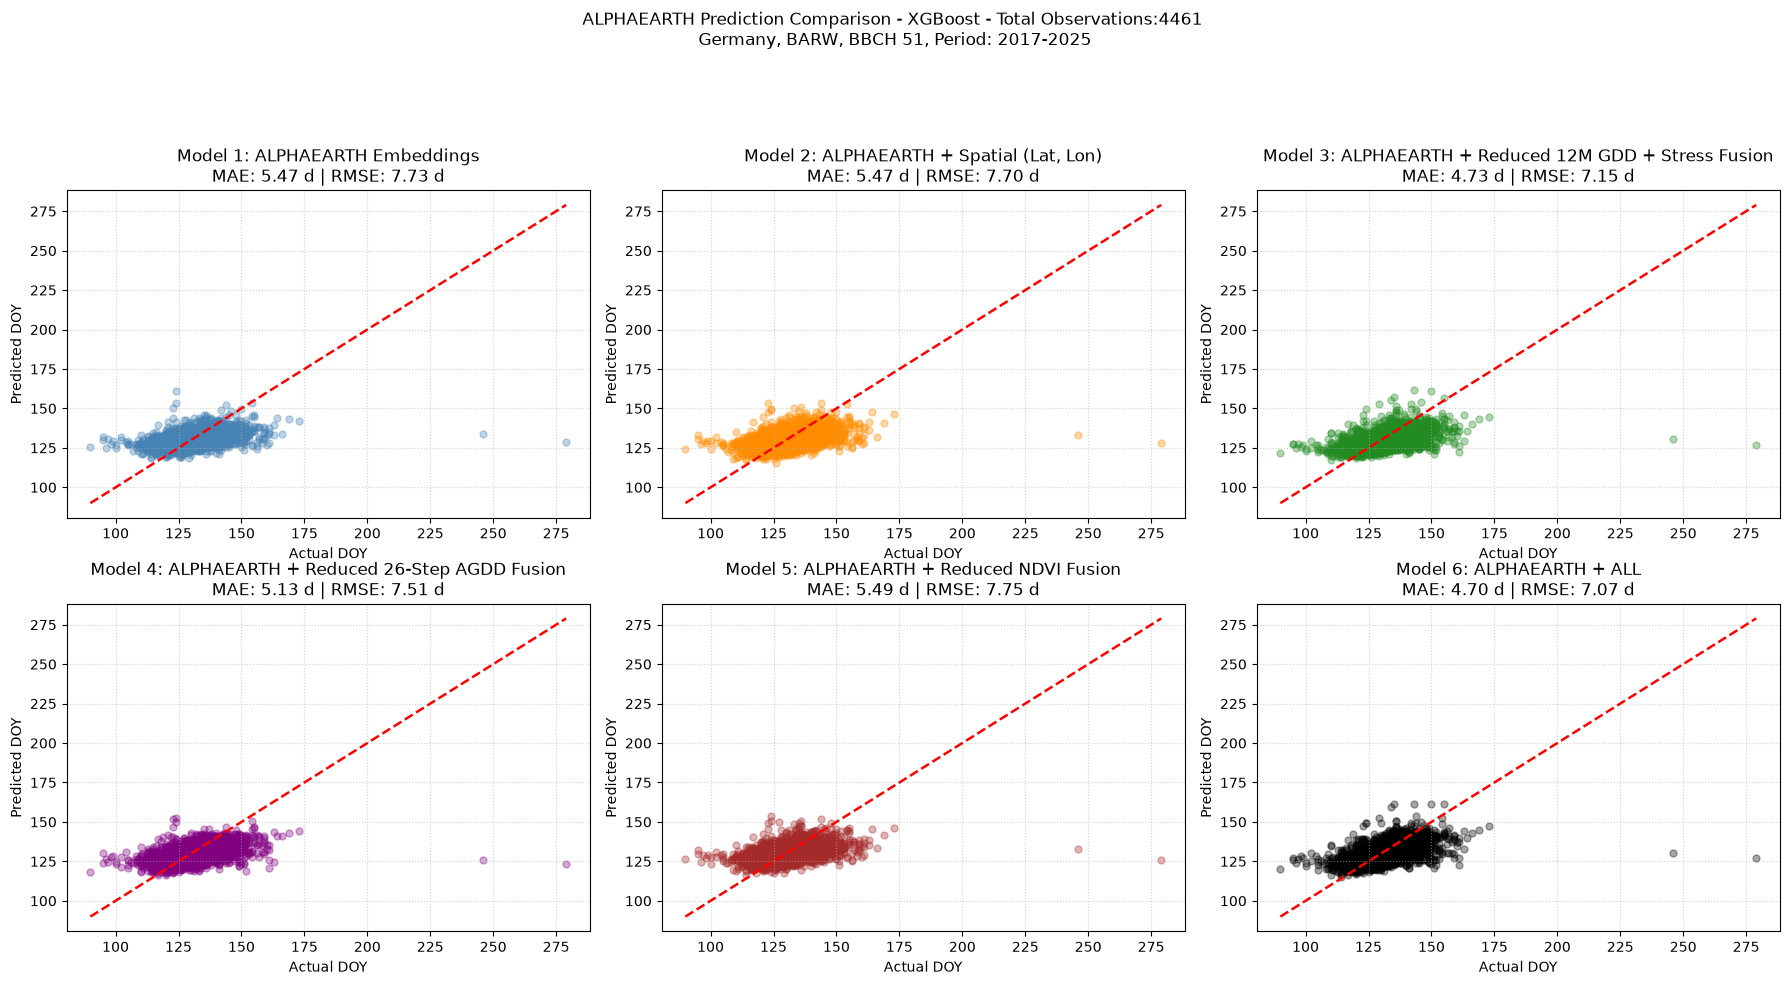

In [40]:
df_folds = pd.DataFrame(fold_results)

overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))
overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))
overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))
overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))
overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))
overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))

# Print overall results
print(f"\n{'='*80}")
print(f"OVERALL LOYOCV BENCHMARK RESULTS ({selected_folder.name})")
print(f"{'='*80}")
print(f"Model 1: {model} --> Overall MAE:  {overall_m1_mae:.2f} days | Overall RMSE: {overall_m1_rmse:.2f} days")
print(f"Model 2: {model} + Spatial (Lat, Lon) --> Overall MAE:  {overall_m2_mae:.2f} days | Overall RMSE: {overall_m2_rmse:.2f} days")
print(f"Model 3: {model} + Reduced 12M GDD + Stress Fusion --> Overall MAE:  {overall_m3_mae:.2f} days | Overall RMSE: {overall_m3_rmse:.2f} days")
print(f"Model 4: {model} + Reduced 26-Step AGDD Fusion --> Overall MAE:  {overall_m4_mae:.2f} days | Overall RMSE: {overall_m4_rmse:.2f} days")
print(f"Model 5: {model} + Reduced NDVI Fusion --> Overall MAE:  {overall_m5_mae:.2f} days | Overall RMSE: {overall_m5_rmse:.2f} days")
print(f"Model 6: {model} + ALL --> Overall MAE:  {overall_m6_mae:.2f} days | Overall RMSE: {overall_m6_rmse:.2f} days")

display(df_folds)

results_path_filtered = summary_save_path / f"{model.lower()}_loyocv_results_xgboost_reduced.csv"
df_folds.to_csv(results_path_filtered, sep=";", index=False)

# Scatter plots for the 5 baselines 
plt.figure(figsize=(18, 10))

models_plot = [
    (f"Model 1: {model} Embeddings", m1_preds, overall_m1_mae, overall_m1_rmse, "steelblue"),
    (f"Model 2: {model} + Spatial (Lat, Lon)", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + Reduced 12M GDD + Stress Fusion", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + Reduced 26-Step AGDD Fusion", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + Reduced NDVI Fusion", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL", m6_preds, overall_m6_mae, overall_m6_rmse, "black")]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(2, 3, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
    plt.plot([min(actual_doy), max(actual_doy)], [min(actual_doy), max(actual_doy)], "r--", lw=1.8, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
    plt.xlabel("Actual DOY")
    plt.ylabel("Predicted DOY")
    plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.suptitle(f"{model} Prediction Comparison - XGBoost - Total Observations:{len(df_clean)} \n{final_name}")
# Save plot
plt.savefig(summary_save_path / f"scatter_comparison_{model.lower()}_xgboost_reduced", dpi=300, bbox_inches="tight")
plt.show()

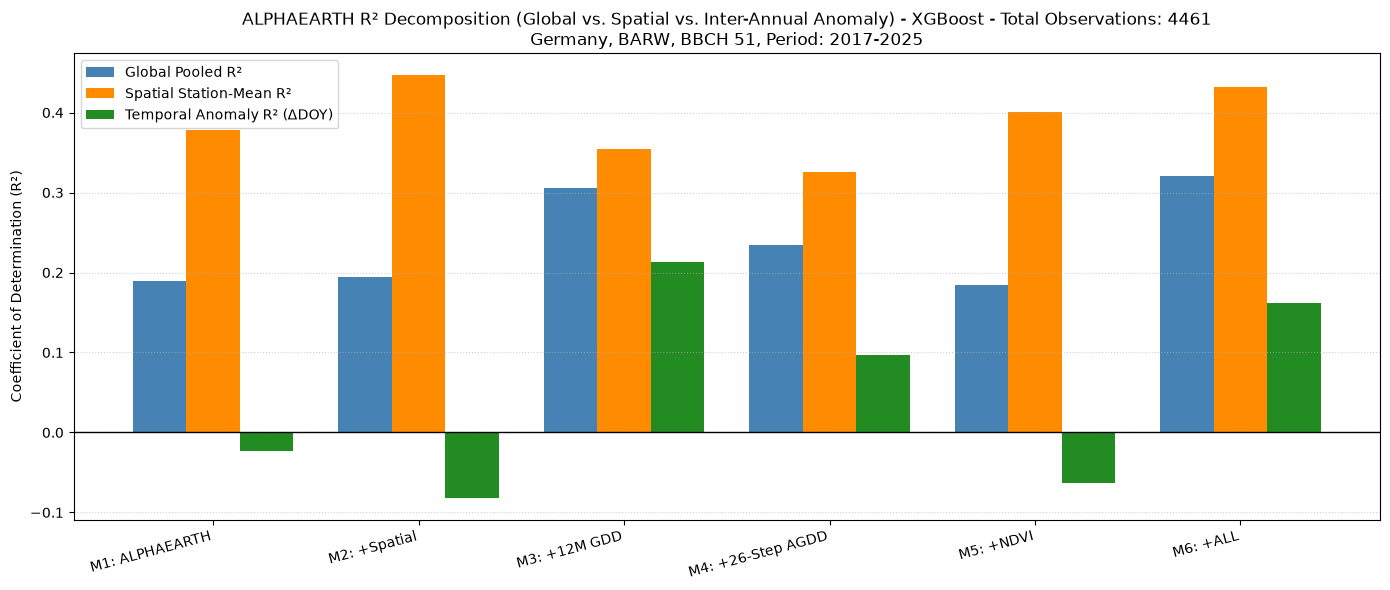

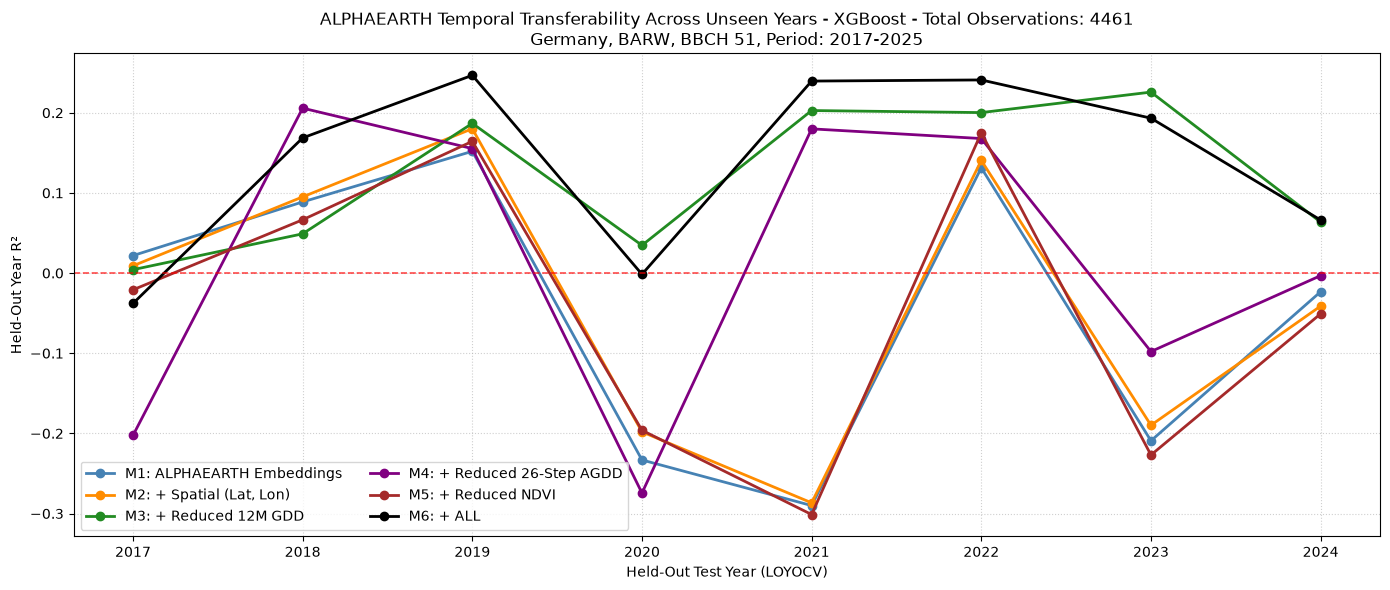

In [41]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_clean to separate spatial vs. temporal variance
if "PEP_ID" in df_clean.columns:
  station_ids = df_clean["PEP_ID"].values
else:
  station_ids = (
      df_clean["Latitude"].round(4).astype(str)
      + "_"
      + df_clean["Longitude"].round(4).astype(str)
  ).values

years_arr = df_clean["Year"].astype(int).values

# Match your exact prediction variables and model labels
xgb_reduced_models = [
    (f"M1: {model} Embeddings", np.asarray(m1_preds), "steelblue"),
    ("M2: + Spatial (Lat, Lon)", np.asarray(m2_preds), "darkorange"),
    ("M3: + Reduced 12M GDD", np.asarray(m3_preds), "forestgreen"),
    ("M4: + Reduced 26-Step AGDD", np.asarray(m4_preds), "purple"),
    ("M5: + Reduced NDVI", np.asarray(m5_preds), "brown"),
    ("M6: + ALL", np.asarray(m6_preds), "black"),
]

# -------------------------------------------------------------------------
# 1. R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R²
# -------------------------------------------------------------------------
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    f"M1: {model}",
    "M2: +Spatial",
    "M3: +12M GDD",
    "M4: +26-Step AGDD",
    "M5: +NDVI",
    "M6: +ALL",
]

for _, preds, _ in xgb_reduced_models:
  # 1. Global Pooled R²
  g_r2 = r2_score(actual_doy_arr, preds)

  # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
  df_tmp = pd.DataFrame({
      "Station": station_ids,
      "Actual": actual_doy_arr,
      "Pred": preds,
  })
  st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
  s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

  df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
  obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
  pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
  t_r2 = r2_score(obs_anom, pred_anom)

  global_r2_list.append(g_r2)
  spatial_r2_list.append(s_r2)
  temporal_r2_list.append(t_r2)

x_pos = np.arange(len(xgb_reduced_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R² (ΔDOY)",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) -"
    f" XGBoost - Total Observations: {len(df_clean)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_decomposition_{model.lower()}_xgboost_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -------------------------------------------------------------------------
# 2. Per-Year LOYOCV R² Trajectory Across Held-Out Years (M1 to M6)
# -------------------------------------------------------------------------
unique_years = sorted(np.unique(years_arr))

plt.figure(figsize=(14, 6))

for m_label, preds, color in xgb_reduced_models:
  yearly_r2 = []
  for yr in unique_years:
    mask = years_arr == yr
    yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

  plt.plot(
      unique_years,
      yearly_r2,
      marker="o",
      lw=2,
      color=color,
      label=m_label,
  )

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"{model} Temporal Transferability Across Unseen Years - XGBoost - Total"
    f" Observations: {len(df_clean)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_per_year_{model.lower()}_xgboost_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Try PCA for TESSERA embeddings for Random Forest & XGBoost - Predictions using the reduced features

Setup models and PCA components for TESSERA

In [42]:
# Number of PCA components for model embeddings
N_PCA_COMPONENTS = 24

baselines = {
    "M1" : [],
    "M2" : ["Latitude", "Longitude"],
    "M3" : [c for c in df_reduced.columns if c.startswith("GDD_")],
    "M4" : [c for c in df_reduced.columns if c.startswith("AGDD_")],
    "M5" : [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")],
    "M6" : ["Latitude", "Longitude"] + [c for c in df_reduced.columns if c.startswith("GDD_")] + 
    [c for c in df_reduced.columns if c.startswith("AGDD_")] + [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")]
}

unique_years = sorted(df_reduced["Year"].unique())
y_all = df_reduced["DOY"]
groups_all = df_reduced["Year"]

LOYOCV Hyperparameter search

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("=" * 80)
print(
    f"RUNNING LOYOCV TUNING (PCA N={N_PCA_COMPONENTS}) FOR RF &"
    " XGBOOST"
)
print("=" * 80)

logo = LeaveOneGroupOut()
best_params_rf = {}
best_params_xgb = {}

for model_key, extra_cols in baselines.items():
  print(f"\n--- Tuning {model_key} ---")

  all_cols = embedding_cols + extra_cols
  X_subset = df_reduced[all_cols]

  # Preprocessor: Standardize & reduce TESSERA; pass other features untouched
  preprocessor = ColumnTransformer(
      transformers=[
          (
              "tessera_pca",
              Pipeline([
                  ("scaler", StandardScaler()),
                  ("pca", PCA(n_components=N_PCA_COMPONENTS, random_state=42)),
              ]),
              embedding_cols,
          ),
          ("passthrough", "passthrough", extra_cols),
      ]
  )

  # 1. Random Forest Tuning Pipeline
  rf_pipeline = Pipeline([
      ("prep", preprocessor),
      ("rf", RandomForestRegressor(random_state=42, n_jobs=-1)),
  ])

  rf_param_dist = {
      "rf__n_estimators": randint(150, 350),
      "rf__max_depth": [None, 10, 15, 20],
      "rf__min_samples_leaf": randint(1, 5),
      "rf__min_samples_split": randint(2, 6),
      "rf__max_features": uniform(0.25, 0.50),
  }

  rf_search = RandomizedSearchCV(
      estimator=rf_pipeline,
      param_distributions=rf_param_dist,
      n_iter=15,
      scoring="neg_mean_absolute_error",
      cv=logo,
      random_state=42,
      n_jobs=-1,
      verbose=0,
  )
  rf_search.fit(X_subset, y_all, groups=groups_all)
  best_params_rf[model_key] = {
      k.replace("rf__", ""): v for k, v in rf_search.best_params_.items()
  }
  print(f" -> Best RF LOYOCV MAE: {-rf_search.best_score_:.2f} days")

  # 2. XGBoost Tuning Pipeline
  xgb_pipeline = Pipeline([
      ("prep", preprocessor),
      (
          "xgb",
          XGBRegressor(
              random_state=42,
              n_jobs=-1,
              tree_method="hist",
              device="cuda",  # Will run on GPU if available, falls back to CPU
          ),
      ),
  ])

  xgb_param_dist = {
      "xgb__n_estimators": randint(100, 300),
      "xgb__max_depth": randint(3, 8),
      "xgb__learning_rate": uniform(0.01, 0.08),
      "xgb__subsample": uniform(0.6, 0.4),
      "xgb__colsample_bytree": uniform(0.5, 0.5),
  }

  xgb_search = RandomizedSearchCV(
      estimator=xgb_pipeline,
      param_distributions=xgb_param_dist,
      n_iter=15,
      scoring="neg_mean_absolute_error",
      cv=logo,
      random_state=42,
      n_jobs=-1,
      verbose=0,
  )
  xgb_search.fit(X_subset, y_all, groups=groups_all)
  best_params_xgb[model_key] = {
      k.replace("xgb__", ""): v for k, v in xgb_search.best_params_.items()
  }
  print(f" -> Best XGB LOYOCV MAE: {-xgb_search.best_score_:.2f} days")

RUNNING LOYOCV TUNING (PCA N=24) FOR RF & XGBOOST

--- Tuning M1 ---
 -> Best RF LOYOCV MAE: 5.52 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:12:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:12:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 5.53 days

--- Tuning M2 ---
 -> Best RF LOYOCV MAE: 5.51 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:14:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:14:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 5.51 days

--- Tuning M3 ---
 -> Best RF LOYOCV MAE: 4.83 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:17:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:17:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


... (3 outputs left out)

c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:25:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:25:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 5.57 days

--- Tuning M6 ---
 -> Best RF LOYOCV MAE: 4.85 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 4.83 days


LOYOCV Evaluation Loop

In [44]:
# Containers for predictions
rf_preds = {k: [] for k in baselines.keys()}
xgb_preds = {k: [] for k in baselines.keys()}

actual_doy = []
test_years_list = []
fold_results_rf = []
fold_results_xgb = []

print(
    f"\nStarting Leak-Free LOYOCV across {len(unique_years)} folds with PCA"
    f" (N={N_PCA_COMPONENTS})...\n"
)

for test_year in unique_years:
  train_mask = df_reduced["Year"] != test_year
  test_mask = df_reduced["Year"] == test_year

  y_train = df_reduced.loc[train_mask, "DOY"]
  y_test = df_reduced.loc[test_mask, "DOY"]

  # Scaling & PCA transformation strictly on training fold
  scaler = StandardScaler()
  embedding_train_scaled = scaler.fit_transform(
      df_reduced.loc[train_mask, embedding_cols]
  )
  embedding_test_scaled = scaler.transform(df_reduced.loc[test_mask, embedding_cols])

  pca = PCA(n_components=N_PCA_COMPONENTS, random_state=42)
  embedding_train_pca = pca.fit_transform(embedding_train_scaled)
  embedding_test_pca = pca.transform(embedding_test_scaled)

  pca_col_names = [f"{model}_pca_{i}" for i in range(N_PCA_COMPONENTS)]
  df_pca_train = pd.DataFrame(
      embedding_train_pca,
      columns=pca_col_names,
      index=df_reduced[train_mask].index,
  )
  df_pca_test = pd.DataFrame(
      embedding_test_pca, columns=pca_col_names, index=df_reduced[test_mask].index
  )

  # Train and evaluate all 6 baseline combinations for both models
  fold_row_rf = {"Test_Year": test_year, "N_Samples": len(y_test)}
  fold_row_xgb = {"Test_Year": test_year, "N_Samples": len(y_test)}

  for model_key, extra_cols in baselines.items():
    if extra_cols:
      X_tr = pd.concat(
          [df_pca_train, df_reduced.loc[train_mask, extra_cols]], axis=1
      )
      X_te = pd.concat(
          [df_pca_test, df_reduced.loc[test_mask, extra_cols]], axis=1
      )
    else:
      X_tr = df_pca_train
      X_te = df_pca_test

    # 1. Random Forest
    rf_mod = RandomForestRegressor(
        **best_params_rf[model_key], random_state=42, n_jobs=-1
    )
    rf_mod.fit(X_tr, y_train)
    p_rf = rf_mod.predict(X_te)
    rf_preds[model_key].extend(p_rf)

    mae_rf = mean_absolute_error(y_test, p_rf)
    rmse_rf = np.sqrt(mean_squared_error(y_test, p_rf))
    fold_row_rf[f"{model_key}_MAE"] = round(mae_rf, 2)
    fold_row_rf[f"{model_key}_RMSE"] = round(rmse_rf, 2)

    # 2. XGBoost
    xgb_mod = XGBRegressor(
        **best_params_xgb[model_key],
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        device="cuda",
    )
    xgb_mod.fit(X_tr, y_train)
    p_xgb = xgb_mod.predict(X_te)
    xgb_preds[model_key].extend(p_xgb)

    mae_xgb = mean_absolute_error(y_test, p_xgb)
    rmse_xgb = np.sqrt(mean_squared_error(y_test, p_xgb))
    fold_row_xgb[f"{model_key}_MAE"] = round(mae_xgb, 2)
    fold_row_xgb[f"{model_key}_RMSE"] = round(rmse_xgb, 2)

  fold_results_rf.append(fold_row_rf)
  fold_results_xgb.append(fold_row_xgb)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
      f"Year {test_year} (N={len(y_test):3d}) | "
      f"RF M1: {fold_row_rf['M1_MAE']:5.2f}d, M4: {fold_row_rf['M4_MAE']:5.2f}d, M6: {fold_row_rf['M6_MAE']:5.2f}d | "
      f"XGB M1: {fold_row_xgb['M1_MAE']:5.2f}d, M4: {fold_row_xgb['M4_MAE']:5.2f}d, M6: {fold_row_xgb['M6_MAE']:5.2f}d"
  )

print("\nLOYOCV execution with PCA finished!")


Starting Leak-Free LOYOCV across 8 folds with PCA (N=24)...



c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02

Year 2017 (N=621) | RF M1:  4.36d, M4:  5.58d, M6:  4.02d | XGB M1:  4.37d, M4:  5.22d, M6:  4.47d


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:32:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02

Year 2018 (N=598) | RF M1:  4.81d, M4:  4.22d, M6:  4.34d | XGB M1:  4.72d, M4:  4.29d, M6:  4.62d


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:33:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:33:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:33:05] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02

... (7 outputs left out)

c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:34:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:34:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:34:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02

Year 2023 (N=511) | RF M1:  5.07d, M4:  4.49d, M6:  3.97d | XGB M1:  5.28d, M4:  6.18d, M6:  4.39d


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:34:37] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:34:37] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:34:39] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [02

Year 2024 (N=488) | RF M1:  7.03d, M4:  6.38d, M6:  5.84d | XGB M1:  7.06d, M4:  6.08d, M6:  5.75d

LOYOCV execution with PCA finished!


Benchamrk Sumarry & Plots

OVERALL LOYOCV BENCHMARK: ALPHAEARTH REDUCED (PCA 24-d)
Model M1 | RF MAE:  5.49d, RMSE:  7.78d | XGB MAE:  5.50d, RMSE:  7.79d
Model M2 | RF MAE:  5.47d, RMSE:  7.76d | XGB MAE:  5.46d, RMSE:  7.74d
Model M3 | RF MAE:  4.82d, RMSE:  7.22d | XGB MAE:  4.78d, RMSE:  7.19d
Model M4 | RF MAE:  5.34d, RMSE:  7.73d | XGB MAE:  5.33d, RMSE:  7.73d
Model M5 | RF MAE:  5.54d, RMSE:  7.84d | XGB MAE:  5.56d, RMSE:  7.88d
Model M6 | RF MAE:  4.85d, RMSE:  7.26d | XGB MAE:  4.93d, RMSE:  7.36d

Summaries successfully saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_ALPHAEARTH_PCA


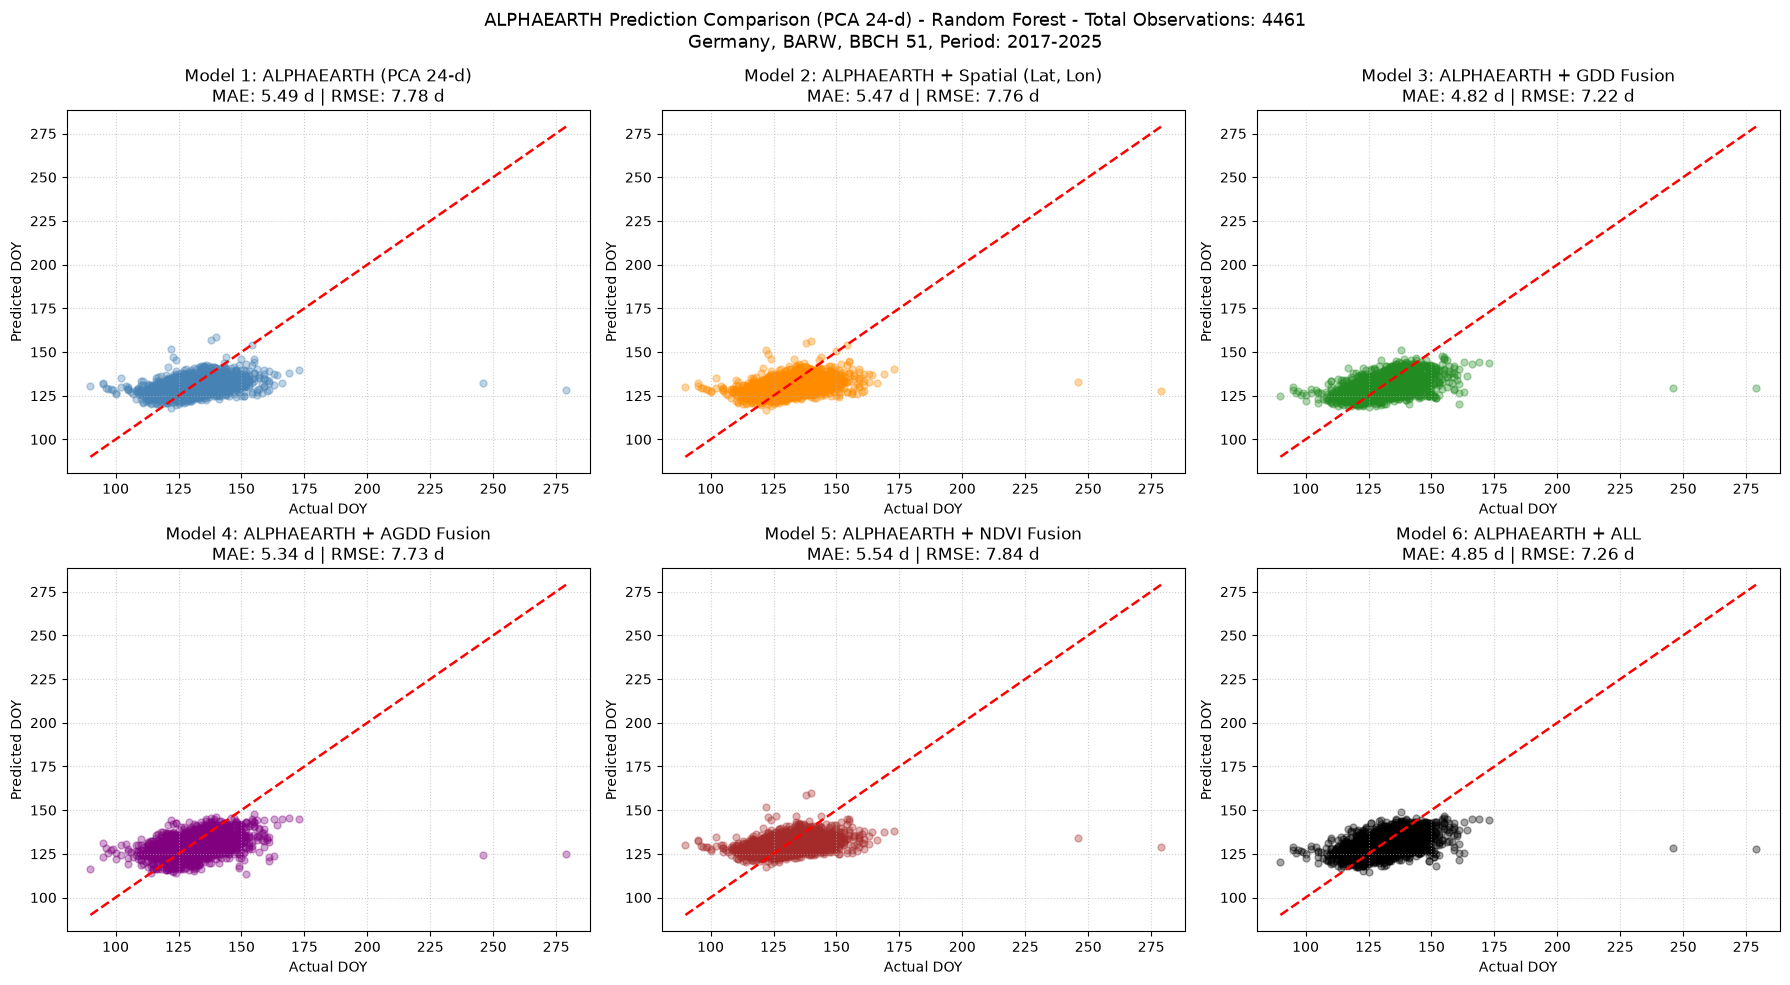

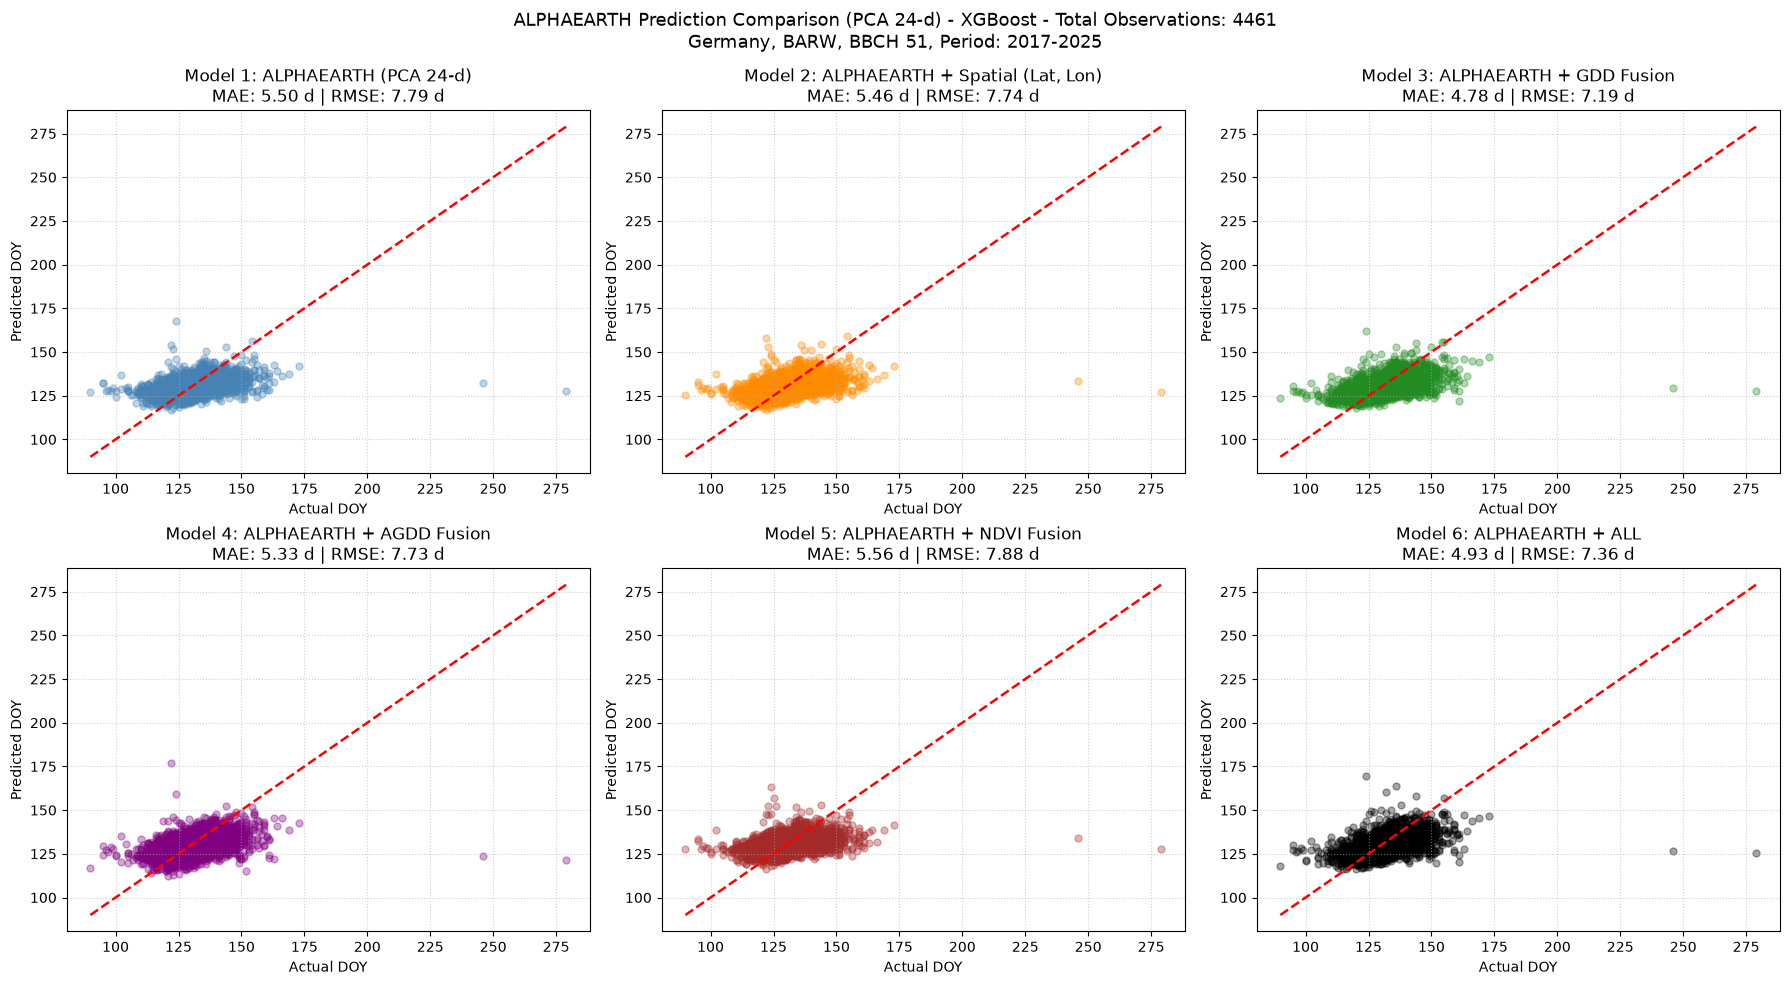

In [45]:
results_dir = Path("Results")
summary_save_path = (
    results_dir / f"{selected_folder.name}" / f"LOYOCV_{model}_PCA"
)
summary_save_path.mkdir(parents=True, exist_ok=True)

df_folds_rf = pd.DataFrame(fold_results_rf)
df_folds_xgb = pd.DataFrame(fold_results_xgb)

print("=" * 85)
print(f"OVERALL LOYOCV BENCHMARK: {model} REDUCED (PCA {N_PCA_COMPONENTS}-d)")
print("=" * 85)

for model_key in baselines.keys():
  mae_rf = mean_absolute_error(actual_doy, rf_preds[model_key])
  rmse_rf = np.sqrt(mean_squared_error(actual_doy, rf_preds[model_key]))
  mae_xgb = mean_absolute_error(actual_doy, xgb_preds[model_key])
  rmse_xgb = np.sqrt(mean_squared_error(actual_doy, xgb_preds[model_key]))

  print(
      f"Model {model_key} | RF MAE: {mae_rf:5.2f}d, RMSE: {rmse_rf:5.2f}d |"
      f" XGB MAE: {mae_xgb:5.2f}d, RMSE: {rmse_xgb:5.2f}d"
  )

# Export fold-level summaries
df_folds_rf.to_csv(summary_save_path / f"{model.lower()}summary_rf_pca.csv", sep=";", index=False)
df_folds_xgb.to_csv(
    summary_save_path / f"{model.lower()}_summary_xgboost_pca.csv", sep=";", index=False
)

print(f"\nSummaries successfully saved to: {summary_save_path.resolve()}")

# Plots
# 1. Scatter Plots for Random Forest (PCA-Reduced)
plt.figure(figsize=(18, 10))

models_plot_rf = [
    (
        f"Model 1: {model} (PCA {N_PCA_COMPONENTS}-d)",
        rf_preds["M1"],
        mean_absolute_error(actual_doy, rf_preds["M1"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M1"])),
        "steelblue",
    ),
    (
        f"Model 2: {model} + Spatial (Lat, Lon)",
        rf_preds["M2"],
        mean_absolute_error(actual_doy, rf_preds["M2"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M2"])),
        "darkorange",
    ),
    (
        f"Model 3: {model} + GDD Fusion",
        rf_preds["M3"],
        mean_absolute_error(actual_doy, rf_preds["M3"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M3"])),
        "forestgreen",
    ),
    (
        f"Model 4: {model} + AGDD Fusion",
        rf_preds["M4"],
        mean_absolute_error(actual_doy, rf_preds["M4"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M4"])),
        "purple",
    ),
    (
        f"Model 5: {model} + NDVI Fusion",
        rf_preds["M5"],
        mean_absolute_error(actual_doy, rf_preds["M5"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M5"])),
        "brown",
    ),
    (
        f"Model 6: {model} + ALL",
        rf_preds["M6"],
        mean_absolute_error(actual_doy, rf_preds["M6"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M6"])),
        "black",
    ),
]

min_val = min(actual_doy)
max_val = max(actual_doy)

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot_rf, 1):
  plt.subplot(2, 3, i)
  plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
  plt.plot(
      [min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit"
  )
  plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
  plt.xlabel("Actual DOY")
  plt.ylabel("Predicted DOY")
  plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.suptitle(
    f"{model} Prediction Comparison (PCA {N_PCA_COMPONENTS}-d) - Random Forest"
    f" - Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

# Save Random Forest figure
rf_plot_path = (
    summary_save_path / f"scatter_comparison_{model.lower()}_rf_pca_reduced.png"
)
plt.savefig(rf_plot_path, dpi=300, bbox_inches="tight")
plt.show()


# Scatter Plots for XGBoost (PCA-Reduced)
plt.figure(figsize=(18, 10))

models_plot_xgb = [
    (
        f"Model 1: {model} (PCA {N_PCA_COMPONENTS}-d)",
        xgb_preds["M1"],
        mean_absolute_error(actual_doy, xgb_preds["M1"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M1"])),
        "steelblue",
    ),
    (
        f"Model 2: {model} + Spatial (Lat, Lon)",
        xgb_preds["M2"],
        mean_absolute_error(actual_doy, xgb_preds["M2"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M2"])),
        "darkorange",
    ),
    (
        f"Model 3: {model} + GDD Fusion",
        xgb_preds["M3"],
        mean_absolute_error(actual_doy, xgb_preds["M3"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M3"])),
        "forestgreen",
    ),
    (
        f"Model 4: {model} + AGDD Fusion",
        xgb_preds["M4"],
        mean_absolute_error(actual_doy, xgb_preds["M4"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M4"])),
        "purple",
    ),
    (
        f"Model 5: {model} + NDVI Fusion",
        xgb_preds["M5"],
        mean_absolute_error(actual_doy, xgb_preds["M5"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M5"])),
        "brown",
    ),
    (
        f"Model 6: {model} + ALL",
        xgb_preds["M6"],
        mean_absolute_error(actual_doy, xgb_preds["M6"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M6"])),
        "black",
    ),
]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot_xgb, 1):
  plt.subplot(2, 3, i)
  plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
  plt.plot(
      [min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit"
  )
  plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
  plt.xlabel("Actual DOY")
  plt.ylabel("Predicted DOY")
  plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.suptitle(
    f"{model} Prediction Comparison (PCA {N_PCA_COMPONENTS}-d) - XGBoost -"
    f" Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

# Save XGBoost figure
xgb_plot_path = (
    summary_save_path / f"scatter_comparison_{model.lower()}_xgboost_pca_reduced.png"
)
plt.savefig(xgb_plot_path, dpi=300, bbox_inches="tight")
plt.show()


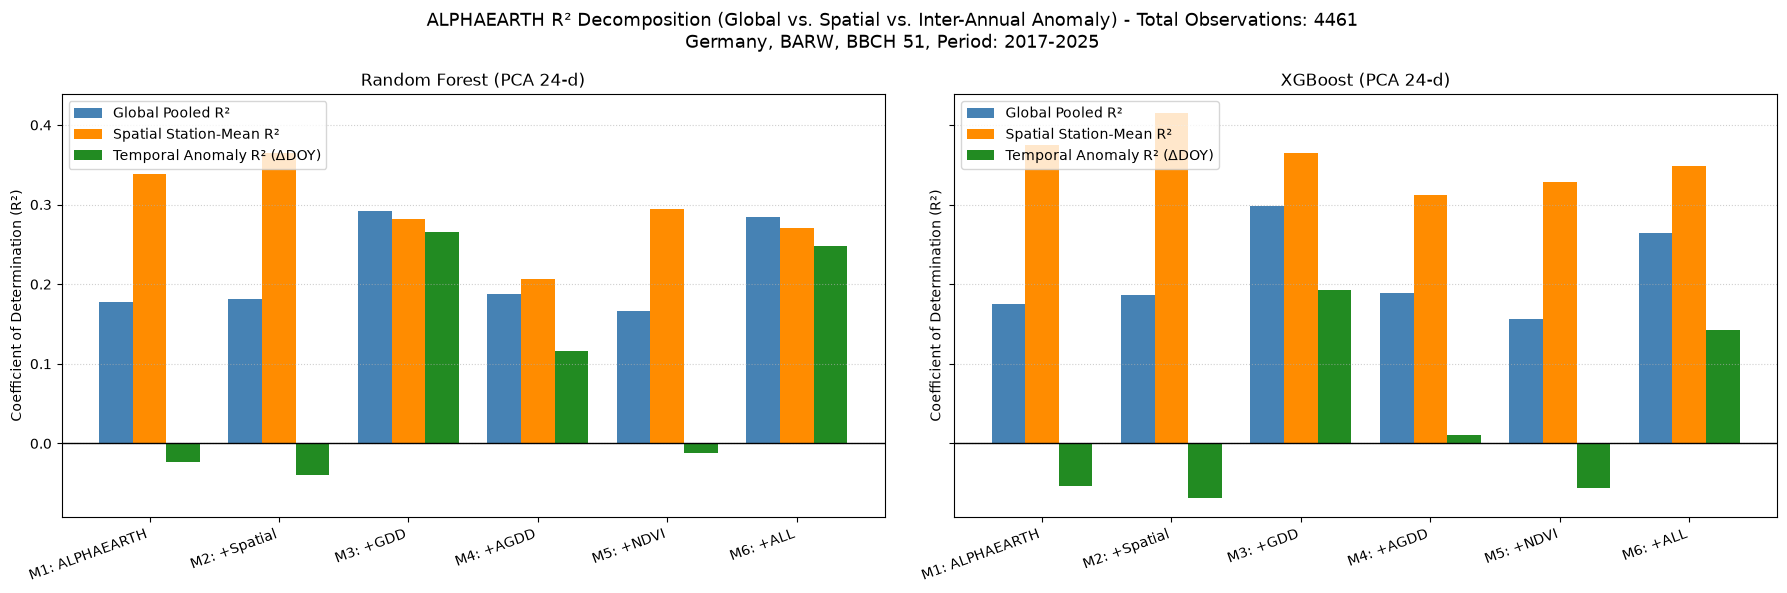

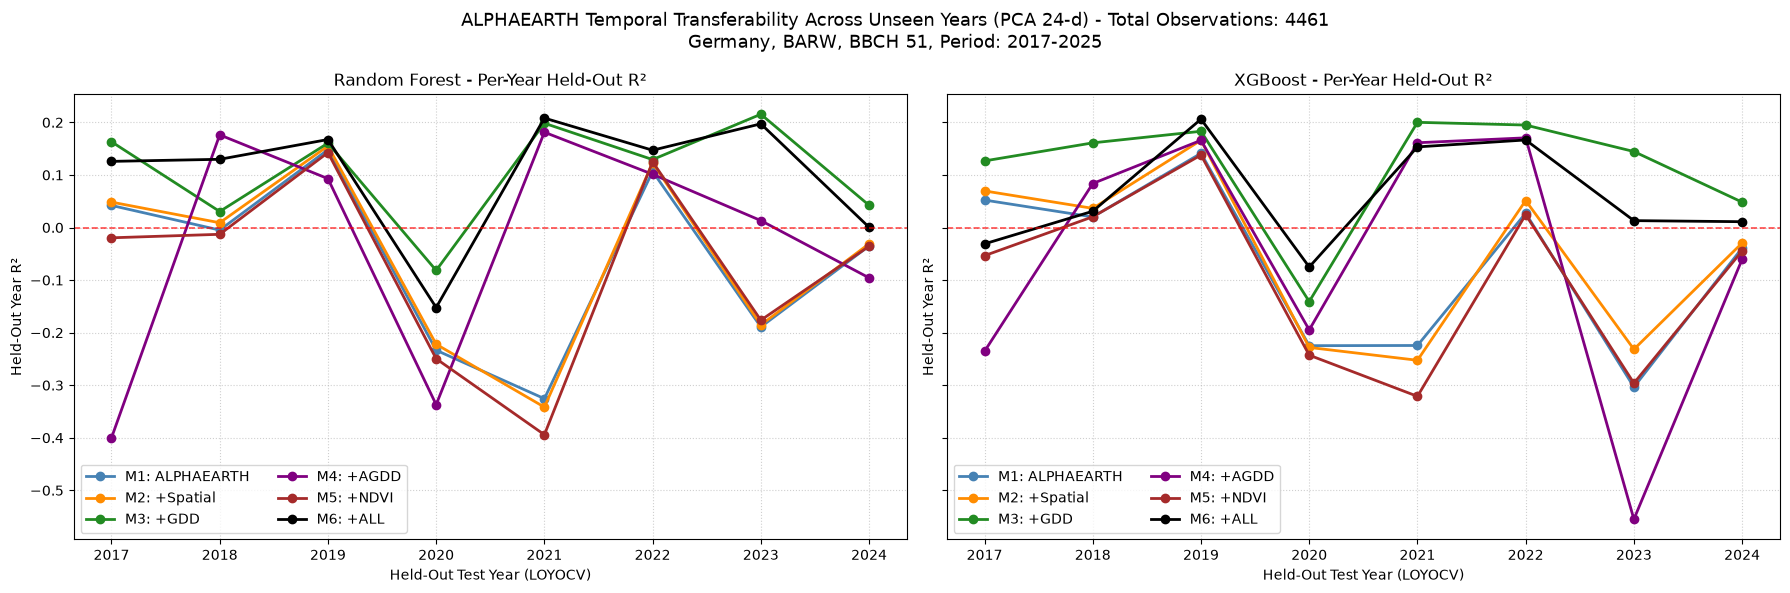

In [ ]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array so boolean masking works cleanly
actual_doy_arr = np.asarray(actual_doy)

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R²
if "PEP_ID" in df_clean.columns:
  station_ids = df_clean["PEP_ID"].values
else:
  station_ids = (
      df_clean["Latitude"].round(4).astype(str)
      + "_"
      + df_clean["Longitude"].round(4).astype(str)
  ).values

years_arr = df_clean["Year"].astype(int).values
model_keys = ["M1", "M2", "M3", "M4", "M5", "M6"]
model_short_labels = [
    f"M1: {model}",
    "M2: +Spatial",
    "M3: +GDD",
    "M4: +AGDD",
    "M5: +NDVI",
    "M6: +ALL",
]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, algo_name, preds_dict in [
    (axes[0], "Random Forest", rf_preds),
    (axes[1], "XGBoost", xgb_preds),
]:
  global_r2_list = []
  spatial_r2_list = []
  temporal_r2_list = []

  for m_key in model_keys:
    preds = np.asarray(preds_dict[m_key])

    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

  x_pos = np.arange(len(model_keys))
  bar_width = 0.26

  ax.bar(
      x_pos - bar_width,
      global_r2_list,
      width=bar_width,
      label="Global Pooled R²",
      color="steelblue",
  )
  ax.bar(
      x_pos,
      spatial_r2_list,
      width=bar_width,
      label="Spatial Station-Mean R²",
      color="darkorange",
  )
  ax.bar(
      x_pos + bar_width,
      temporal_r2_list,
      width=bar_width,
      label="Temporal Anomaly R² (ΔDOY)",
      color="forestgreen",
  )

  ax.axhline(0, color="black", lw=1.0)
  ax.set_xticks(x_pos)
  ax.set_xticklabels(model_short_labels, rotation=20, ha="right")
  ax.set_title(f"{algo_name} (PCA {N_PCA_COMPONENTS}-d)")
  ax.set_ylabel("Coefficient of Determination (R²)")
  ax.grid(True, axis="y", linestyle=":", alpha=0.6)
  ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.subplots_adjust(top=0.84)
plt.suptitle(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) -"
    f" Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

r2_decomp_path = (
    summary_save_path / f"r2_decomposition_{model.lower()}_pca_reduced.png"
)
plt.savefig(r2_decomp_path, dpi=300, bbox_inches="tight")
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (M1 to M6)
unique_years = sorted(np.unique(years_arr))
line_colors = [
    "steelblue",
    "darkorange",
    "forestgreen",
    "purple",
    "brown",
    "black",
]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, algo_name, preds_dict in [
    (axes[0], "Random Forest", rf_preds),
    (axes[1], "XGBoost", xgb_preds),
]:
  for m_key, m_label, color in zip(model_keys, model_short_labels, line_colors):
    preds = np.asarray(preds_dict[m_key])
    yearly_r2 = []
    for yr in unique_years:
      mask = years_arr == yr
      yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    ax.plot(
        unique_years,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

  ax.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
  ax.set_title(f"{algo_name} - Per-Year Held-Out R²")
  ax.set_xlabel("Held-Out Test Year (LOYOCV)")
  ax.set_ylabel("Held-Out Year R²")
  ax.set_xticks(unique_years)
  ax.grid(True, linestyle=":", alpha=0.6)
  ax.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.subplots_adjust(top=0.84)
plt.suptitle(
    f"{model} Temporal Transferability Across Unseen Years (PCA"
    f" {N_PCA_COMPONENTS}-d) - Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

r2_yearly_path = (
    summary_save_path / f"r2_per_year_{model.lower()}_pca_reduced.png"
)
plt.savefig(r2_yearly_path, dpi=300, bbox_inches="tight")
plt.show()